# Estatística Geral

## Probabilidade


### Axiomas:

Seja Ω o espaço amostral de um experimento e A um evento qualquer. Uma função P, que associa a cada evento um número P(A), é uma probabilidade quando cumpre três regras:
- 0 ≤ P(A) ≤ 1;
- P(Ω) = 1;
- se A1, A2, A3, ... são disjuntos (não podem ocorrer ao mesmo tempo), P(A1 ∪ A2 ∪ A3 ∪ ...) = P(A1) + P(A2) + P(A3) + ...

### Atribuição de probabilidade pela visão clássica:

Quando o experimento tem n resultados possíveis, todos igualmente prováveis, a probabilidade de um evento A é a fração desses resultados que fazem A acontecer. Se f dos n resultados são favoráveis a A:

$$P(A) = \frac{f}{n} = \frac{\text{nº de pontos amostrais favoráveis a } A}{\text{nº total de pontos amostrais}}$$

Por exemplo, numa moeda equilibrada há dois resultados igualmente prováveis, cara e coroa, então P(cara) = P(coroa) = 1/2.

### Atribuição de probabilidade pela visão frequentista:

Se o experimento pode ser repetido muitas vezes, nas mesmas condições e de forma independente, a probabilidade de A é estimada pela frequência relativa com que A ocorreu:

$$P(A) \approx \frac{n_A}{n} = \frac{\text{nº de vezes em que } A \text{ ocorreu}}{\text{nº total de repetições do experimento}}$$

A aproximação fica melhor à medida que o número de repetições $n$ cresce.

Exemplo 1 (dados fictícios, apenas ilustrativos): uma loja virtual classificou as 2000 devoluções do último ano pelo motivo informado pelo cliente:

| Motivo da devolução | Frequência |
|---|---|
| Tamanho errado (T) | 540 |
| Defeito de fabricação (F) | 312 |
| Arrependimento (A) | 228 |
| Atraso na entrega (E) | 186 |
| Produto diferente do anunciado (D) | 414 |
| Outros motivos (O) | 320 |
| Total | 2000 |

Sorteando uma devolução ao acaso, a probabilidade de o motivo ter sido:
- produto diferente do anunciado: P(D) = 414/2000 = 0,207;
- tamanho errado: P(T) = 540/2000 = 0,27.

In [2]:
DATASET = [540, 312, 228, 186, 414, 320]

In [6]:
P_D = DATASET[4] / sum(DATASET)
P_D

0.207

### Interseção de eventos:

A interseção A ∩ B é o evento "A e B acontecem juntos": reúne os resultados que pertencem aos dois eventos ao mesmo tempo.

O diagrama abaixo destaca $A \cap B$:

In [1]:
# Funções auxiliares usadas para desenhar os diagramas e gráficos deste notebook
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm


def virgula(ax):
    """Mostra os números dos eixos com vírgula decimal."""
    fmt = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)


def diagrama_venn(destaque):
    """Diagrama de Venn de dois eventos A e B no espaço amostral Ω.
    destaque: 'intersecao', 'uniao', 'disjuntos' ou 'complementares'."""
    fig, ax = plt.subplots(figsize=(4, 2.6))
    cinza = "0.65"
    if destaque == "complementares":
        ax.add_patch(Rectangle((0, 0), 10, 6, fc=cinza, ec="k", lw=1.5))
        ax.add_patch(Ellipse((6.5, 3.2), 3.6, 2.4, fc="white", ec="k"))
        ax.text(0.4, 5.1, "A", fontsize=12)
        ax.text(7.9, 4.5, "B", fontsize=12)
    elif destaque == "disjuntos":
        ax.add_patch(Rectangle((0, 0), 10, 6, fill=False, lw=1.5))
        ax.add_patch(Ellipse((3, 3.6), 3, 2.4, fc="0.45", ec="k"))
        ax.add_patch(Ellipse((7.2, 2.0), 3, 2.0, fc="0.8", ec="k"))
        ax.text(1.0, 4.9, "A", fontsize=12)
        ax.text(8.9, 0.6, "B", fontsize=12)
    else:
        ax.add_patch(Rectangle((0, 0), 10, 6, fill=False, lw=1.5))
        if destaque == "uniao":
            ax.add_patch(Ellipse((3.9, 3), 4.2, 3, fc=cinza, ec="none"))
            ax.add_patch(Ellipse((6.1, 3), 4.2, 3, fc=cinza, ec="none"))
        elif destaque == "intersecao":
            recorte = Ellipse((3.9, 3), 4.2, 3, fill=False, ec="none")
            ax.add_patch(recorte)
            miolo = Ellipse((6.1, 3), 4.2, 3, fc="0.45", ec="none")
            ax.add_patch(miolo)
            miolo.set_clip_path(recorte)
        ax.add_patch(Ellipse((3.9, 3), 4.2, 3, fill=False, ec="k"))
        ax.add_patch(Ellipse((6.1, 3), 4.2, 3, fill=False, ec="k"))
        ax.text(1.0, 4.8, "A", fontsize=12)
        ax.text(8.6, 4.8, "B", fontsize=12)
    ax.text(0.3, 0.3, "Ω", fontsize=12)
    ax.set_xlim(-0.2, 10.2)
    ax.set_ylim(-0.2, 6.2)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.show()


def arvore(ramos, largura_notas=2.2, figsize=(6.5, 4)):
    """Desenha uma árvore de probabilidades.
    Cada ramo é uma tupla (rótulo, probabilidade em texto, sub-ramos, anotação)."""
    fig, ax = plt.subplots(figsize=figsize)
    contador = [0]

    def posicionar(ramo, nivel):
        rotulo, prob, sub, nota = ramo
        filhos = [posicionar(r, nivel + 1) for r in sub]
        if filhos:
            y = np.mean([f["y"] for f in filhos])
        else:
            y = -contador[0]
            contador[0] += 1
        return {"x": nivel, "y": y, "rotulo": rotulo, "prob": prob, "nota": nota, "filhos": filhos}

    nos = [posicionar(r, 1) for r in ramos]
    y_raiz = np.mean([n["y"] for n in nos])
    nivel_max = [1]

    def desenhar(x0, y0, filhos):
        for n in filhos:
            nivel_max[0] = max(nivel_max[0], n["x"])
            inicio = x0 + (0.06 if x0 == 0 else 0.22)  # depois do rótulo do nó pai
            ax.plot([inicio, n["x"] - 0.14], [y0, n["y"]], color="0.35", lw=1)
            desce = n["y"] < y0  # ramo descendente: rótulo abaixo da linha
            ax.text((x0 + n["x"]) / 2 - 0.1, (y0 + n["y"]) / 2 + (-0.1 if desce else 0.1), n["prob"],
                    ha="center", va="top" if desce else "bottom", fontsize=9, color="tab:blue")
            ax.text(n["x"], n["y"], n["rotulo"], ha="center", va="center", fontsize=11)
            if n["nota"]:
                ax.text(n["x"] + 0.3, n["y"], n["nota"], va="center", fontsize=9)
            desenhar(n["x"], n["y"], n["filhos"])

    desenhar(0, y_raiz, nos)
    ax.plot(0, y_raiz, "o", color="0.35", ms=4)
    ax.set_xlim(-0.2, nivel_max[0] + largura_notas)
    ax.set_ylim(-contador[0] + 0.5, 0.6)
    ax.axis("off")
    plt.show()


def area_normal(a, b, titulo, mu=0, sigma=1, figsize=(5, 2.6)):
    """Sombreia a área entre a e b sob a curva normal (use np.inf para caudas)."""
    x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(x, norm.pdf(x, mu, sigma), color="tab:blue")
    xs = np.linspace(max(a, x[0]), min(b, x[-1]), 300)
    ax.fill_between(xs, norm.pdf(xs, mu, sigma), color="tab:blue", alpha=0.3)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    virgula(ax)
    plt.show()

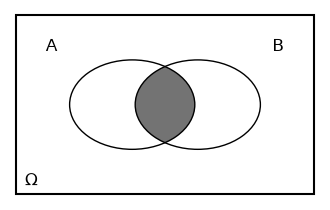

In [2]:
diagrama_venn("intersecao")

### Eventos disjuntos ou mutuamente exclusivos:

A e B são disjuntos quando não têm nenhum resultado em comum: se um deles ocorre, o outro não pode ocorrer.

No diagrama abaixo, $A$ e $B$ não se sobrepõem, ou seja, $A \cap B = \varnothing$:

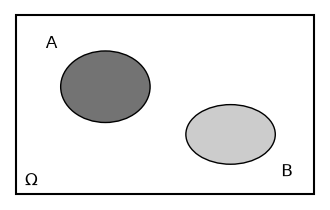

In [3]:
diagrama_venn("disjuntos")

### União de eventos:

A união A ∪ B é o evento "pelo menos um dos dois acontece": A, B ou ambos.

O diagrama abaixo destaca $A \cup B$:

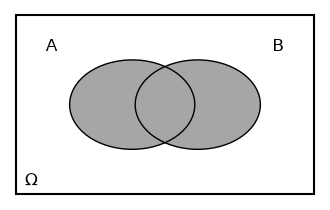

In [4]:
diagrama_venn("uniao")

A probabilidade da união soma as duas probabilidades e desconta a interseção, que seria contada duas vezes:

$$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

### Eventos complementares:

A e B são complementares quando, juntos, cobrem todo o espaço amostral e não têm nada em comum: em qualquer realização do experimento, exatamente um dos dois acontece. No diagrama a seguir, A é tudo o que está fora de B.

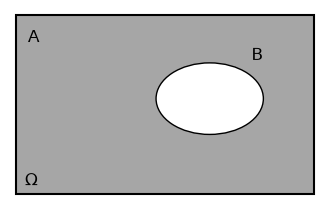

In [5]:
diagrama_venn("complementares")

- Em símbolos, A e B são complementares quando:
$A \cup B = \Omega$ e $A \cap B = \varnothing$.

- O complementar de A, indicado por $A^c$, é o evento "A não ocorre". Aqui:

$A^c = B$ e $B^c = A$

- Consequentemente:

$P(A) = 1 - P(B)$ e $P(A^c) = P(B)$

Exemplo (dados fictícios):

Um aplicativo de entregas sorteou 1000 pedidos e classificou cada um pela forma de pagamento e conforme o cliente fosse ou não assinante do plano premium:

| Assinante | Cartão (C) | Pix (X) | Dinheiro (D) | Total |
|---|---|---|---|---|
| Sim (S) | 180 | 240 | 60 | 480 |
| Não ($S^c$) | 220 | 250 | 50 | 520 |
| Total | 400 | 490 | 110 | 1000 |

Sorteando um desses pedidos ao acaso, qual é a probabilidade de que:

- a) o cliente seja assinante;
- b) o pagamento tenha sido feito com cartão;
- c) o cliente não seja assinante e tenha pago com Pix;
- d) o cliente seja assinante ou tenha pago em dinheiro?

Resolução:

- a) $P(S) = \dfrac{480}{1000} = 0{,}48$
- b) $P(C) = \dfrac{400}{1000} = 0{,}40$
- c) $P(S^c \cap X) = \dfrac{250}{1000} = 0{,}25$
- d) $P(S \cup D) = P(S) + P(D) - P(S \cap D) = \dfrac{480}{1000} + \dfrac{110}{1000} - \dfrac{60}{1000} = 0{,}53$

In [3]:
DATASET = [[180, 240, 60, 480],[220, 250, 50, 520],[400, 490, 110, 1000]]

A = DATASET[0][3]/DATASET[2][3]
print(A)
B = DATASET[2][0]/DATASET[2][3]
print(B)
C = DATASET[1][1]/DATASET[2][3]
print(C)
D = (DATASET[0][3]/DATASET[2][3]) + (DATASET[2][2]/DATASET[2][3]) - (DATASET[0][2]/DATASET[2][3])
print(D)

0.48
0.4
0.25
0.53


### Probabilidade condicional:

$P(A \mid B)$ é a probabilidade de A quando já se sabe que B ocorreu. Saber que B ocorreu reduz o espaço amostral a B; dentro dele, a parte em que A também ocorre é $A \cap B$. Por isso:

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}, \quad P(B) > 0$$

### Regra do produto:

$$P(A \cap B) = P(A \mid B) \cdot P(B), \quad P(B) > 0$$

### Independência de eventos:

A e B são independentes quando saber que um deles ocorreu não muda a probabilidade do outro:

$$P(A \mid B) = P(A) \quad \text{e} \quad P(B \mid A) = P(B)$$

Se dois eventos A e B são independentes então:

$$P(A \cap B) = P(A) \cdot P(B)$$

### Teorema da probabilidade total:

Suponha que os eventos A1, A2, ..., An formem uma partição de Ω: são disjuntos dois a dois e, juntos, cobrem todo o espaço amostral, ou seja,

$$\bigcup_{i=1}^{n} A_i = \Omega$$

Se, além disso, P(Ai) > 0 para todo i, qualquer evento B pode ser decomposto nas suas partes dentro de cada Ai:

$$P(B) = P(A_1 \cap B) + P(A_2 \cap B) + \cdots + P(A_n \cap B)$$

Usando a regra do produto em cada parcela:

$$P(B) = \sum_{i=1}^{n} P(A_i) \cdot P(B \mid A_i)$$

### Teorema de Bayes:

Com a mesma partição A1, ..., An (P(Ai) > 0) e um evento B com P(B) > 0, o teorema de Bayes "inverte" a condicional: a partir das probabilidades P(B | Ai) obtemos P(Ai | B):

$$P(A_i \mid B) = \frac{P(A_i \cap B)}{P(B)} = \frac{P(B \mid A_i) \cdot P(A_i)}{P(B \mid A_1) \cdot P(A_1) + P(B \mid A_2) \cdot P(A_2) + \cdots + P(B \mid A_n) \cdot P(A_n)}$$

Para ver por que vale, observe que

$$P(A_i \cap B) = P(B \cap A_i)$$

e que a regra do produto pode ser aplicada nos dois sentidos:

$$P(B \mid A_i) \cdot P(A_i) = P(A_i \mid B) \cdot P(B)$$

Isso dá o numerador. O denominador é P(B) escrito pelo teorema da probabilidade total.

### Árvore de probabilidades:

É um diagrama em que cada ramificação representa os resultados possíveis de uma etapa, com a probabilidade (condicional) de cada um escrita no ramo. Multiplicando as probabilidades ao longo de um caminho obtemos a probabilidade da interseção correspondente.
- Exemplo:
    Uma torrefação compra grãos de café de três fornecedores: 45% dos sacos vêm de F1, 35% de F2 e 20% de F3. Pelo histórico de inspeções, 4% dos sacos de F1 chegam com umidade acima do limite permitido; para F2 e F3 essas taxas são 6% e 10%. No armazém, os sacos ficam misturados, sem identificação do fornecedor. Sorteando um saco ao acaso, calcule:
    a) A probabilidade de que ele esteja com umidade acima do limite.
    b) A probabilidade de que ele tenha vindo de F3, sabendo que está dentro do limite.

    Resolução:
    O diagrama a seguir representa os três fornecedores (F1, F2 e F3) como uma partição do espaço amostral e o evento A, saco com umidade acima do limite (Ac é o saco dentro do limite):

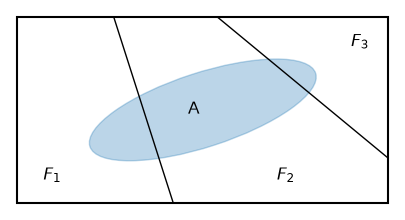

In [6]:
# Partição do espaço amostral pelos fornecedores F1, F2 e F3 e o evento A (umidade acima do limite)
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.add_patch(Rectangle((0, 0), 10, 5, fill=False, lw=1.5))
ax.plot([2.6, 4.2], [5, 0], color="k", lw=1)
ax.plot([5.4, 10], [5, 1.2], color="k", lw=1)
ax.add_patch(Ellipse((5.0, 2.5), 6.4, 2.0, angle=18, fc="tab:blue", alpha=0.3, ec="tab:blue"))
ax.text(4.6, 2.4, "A", fontsize=12)
ax.text(0.7, 0.6, "$F_1$", fontsize=12)
ax.text(7.0, 0.6, "$F_2$", fontsize=12)
ax.text(9.0, 4.2, "$F_3$", fontsize=12)
ax.set_xlim(-0.2, 10.2)
ax.set_ylim(-0.2, 5.2)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

    Seja A o evento "o saco está com umidade acima do limite". Pelo enunciado, P(A|F1) = 0,04, P(A|F2) = 0,06 e P(A|F3) = 0,10, e as probabilidades de cada fornecedor são P(F1) = 0,45, P(F2) = 0,35 e P(F3) = 0,20. Com esses valores montamos a árvore:

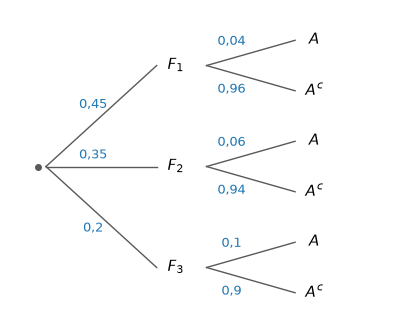

In [7]:
# Árvore de probabilidades: fornecedores (F1, F2, F3) e umidade acima do limite (A) ou não (Aᶜ)
arvore([
    ("$F_1$", "0,45", [("$A$", "0,04", [], None), ("$A^c$", "0,96", [], None)], None),
    ("$F_2$", "0,35", [("$A$", "0,06", [], None), ("$A^c$", "0,94", [], None)], None),
    ("$F_3$", "0,2", [("$A$", "0,1", [], None), ("$A^c$", "0,9", [], None)], None),
], largura_notas=0.6, figsize=(5, 4))

a) Pelo teorema da probabilidade total:

$$P(A) = P(A \mid F_1) \cdot P(F_1) + P(A \mid F_2) \cdot P(F_2) + P(A \mid F_3) \cdot P(F_3)$$

$$P(A) = 0{,}04 \cdot 0{,}45 + 0{,}06 \cdot 0{,}35 + 0{,}10 \cdot 0{,}20 = 0{,}018 + 0{,}021 + 0{,}02 = 0{,}059$$

b) Pelo teorema de Bayes, com $A^c$ = "saco dentro do limite" e $P(A^c) = 1 - P(A)$:

$$P(F_3 \mid A^c) = \frac{P(A^c \mid F_3) \cdot P(F_3)}{1 - P(A)} = \frac{0{,}90 \cdot 0{,}20}{1 - 0{,}059} = \frac{0{,}18}{0{,}941} \approx 0{,}1913$$

### Exercícios:

1. A Tabela 1 mostra os inscritos em quatro oficinas de um evento de tecnologia, separados pela modalidade de participação (dados fictícios).

**Tabela 1** – Inscritos por oficina e modalidade.

| Oficina | Presencial | Online | Total |
|---|---|---|---|
| Python | 45 | 75 | 120 |
| Excel | 30 | 20 | 50 |
| SQL | 15 | 25 | 40 |
| Power BI | 30 | 10 | 40 |
| Total | 120 | 130 | 250 |

Sorteando um inscrito ao acaso, determine a probabilidade de que ele:
a) Participe presencialmente.
b) Esteja inscrito na oficina de SQL.
c) Participe online e esteja inscrito na oficina de Excel.
d) Participe presencialmente ou esteja inscrito na oficina de Power BI.
Respostas: a) 0,48 b) 0,16 c) 0,08 d) 0,52

In [7]:
F_M_T = 120
F_T = 250
P_M_T = F_M_T/F_T
print("a) \f",P_M_T)

a)  0.48


In [8]:
F_E_T = 40
F_T = 250
P_E_T = F_E_T/F_T
print("b) \f",P_E_T)

b)  0.16


In [9]:
F_F_M = 20
F_T = 250
P_F_M = F_F_M/F_T
print("c) \f",P_F_M)

c)  0.08


In [10]:
F_M_T = 120
F_T = 250
P_M_T = F_M_T/F_T

F_C_T = 40
P_C_T = F_C_T/F_T

F_M_C = 30
P_M_C = F_M_C/F_T

P_M_ou_C = P_M_T + P_C_T - P_M_C
print("d) \f",P_M_ou_C)

d)  0.52


2. Uma peça é fabricada em três fábricas, A, B e C. Num certo período, a fábrica A produziu o triplo de peças de B, e B e C produziram a mesma quantidade. Sabe-se que 1% das peças de A, 3% das de B e 5% das de C saem com defeito. Todas as peças vão para o mesmo estoque, de onde uma é retirada ao acaso.
a) Qual é a probabilidade de que a peça seja defeituosa?
b) Sabendo que a peça é perfeita, qual é a probabilidade de que tenha vindo da fábrica B?
Dica: monte a árvore de probabilidades.
Respostas: a) 0,022 b) 0,198

Árvore de probabilidades do exercício 2 (o produto ao longo de cada caminho é a probabilidade da interseção):

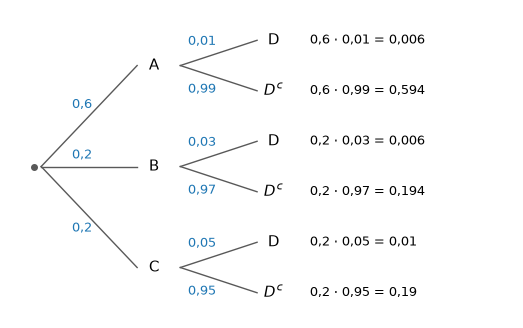

In [8]:
# Árvore de probabilidades do exercício 2: fábrica (A, B, C) e peça defeituosa (D) ou não (Dᶜ)
arvore([
    ("A", "0,6", [("D", "0,01", [], "0,6 · 0,01 = 0,006"), ("$D^c$", "0,99", [], "0,6 · 0,99 = 0,594")], None),
    ("B", "0,2", [("D", "0,03", [], "0,2 · 0,03 = 0,006"), ("$D^c$", "0,97", [], "0,2 · 0,97 = 0,194")], None),
    ("C", "0,2", [("D", "0,05", [], "0,2 · 0,05 = 0,01"), ("$D^c$", "0,95", [], "0,2 · 0,95 = 0,19")], None),
], largura_notas=2.0, figsize=(6.5, 4))

In [11]:
P_A_D = 0.006
P_B_D = 0.006
P_C_D = 0.01
P_D = P_A_D + P_B_D + P_C_D
print("a) \f",P_D)

a)  0.022


In [12]:
P_B_Dc = 0.194
P_Dc = 1 - 0.022   # P_Dc = 1 - P_D
P_B_dado_Dc = P_B_Dc / P_Dc
print("b) \f",P_B_dado_Dc)

b)  0.1983640081799591


3. A tabela abaixo dá probabilidades conjuntas dos eventos A, B e seus complementares; por exemplo, P(A) = 0,25 e P(A e B) = 0,15.

| | $B$ | $B^c$ | Total |
|---|---|---|---|
| $A$ | 0,15 | 0,10 | 0,25 |
| $A^c$ | 0,25 | 0,50 | 0,75 |
| Total | 0,40 | 0,60 | 1,00 |

Verifique se A e B são independentes.
Resposta: como P(A e B) = 0,15 ≠ P(A).P(B) = 0,25 . 0,40 = 0,10, A e B não são independentes.

In [16]:
P_A = 0.25
P_B = 0.4
P_A_B = 0.15

# Para que A e B sejam independentes: P_A_B = P_A * P_B

if P_A_B == P_A * P_B:
    print("A e B são independentes pois P(AeB) = P(A).P(B)")
else:
    print("A e B não são independentes pois P(AeB) ≠ P(A).P(B)")

A e B não são independentes pois P(AeB) ≠ P(A).P(B)


4. Você pede a um colega que envie um relatório pelo sistema interno da empresa. Ele esquece de enviar com probabilidade 0,15. Se ele envia, o sistema perde a mensagem com probabilidade 0,04. Se o sistema entrega, o filtro de spam do destinatário bloqueia a mensagem com probabilidade 0,10.
a) O relatório não chegou. Qual é a probabilidade de que o colega tenha esquecido de enviar?
b) Qual é a probabilidade de o relatório chegar ao destinatário? O que isso diz sobre a confiabilidade desse canal?
Dica: a árvore só se ramifica do lado em que o relatório continua a caminho.
Respostas: a) 0,565 b) 0,734

Eventos: $A$ = o colega esquece de enviar; $B$ = o sistema perde a mensagem; $C$ = o filtro de spam bloqueia a mensagem ($A^c$, $B^c$ e $C^c$ são os complementares). A árvore está na célula abaixo.

$$P(\text{receber}) = 0{,}85 \cdot 0{,}96 \cdot 0{,}90 = 0{,}7344 \qquad P(\text{não receber}) = 1 - 0{,}7344 = 0{,}2656$$

Se o colega esquece, o relatório certamente não chega, então $P(A \cap \text{não receber}) = P(A)$ e

$$P(A \mid \text{não receber}) = \frac{P(A)}{P(\text{não receber})} = \frac{0{,}15}{0{,}2656} \approx 0{,}5648$$

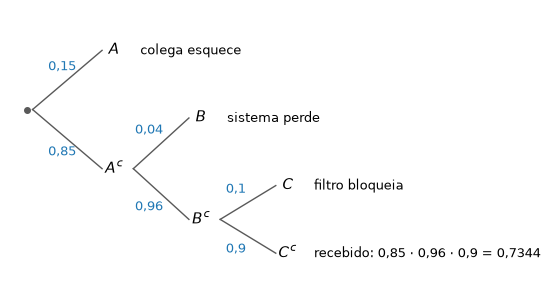

In [9]:
# Árvore de probabilidades do exercício 4: só há ramificação enquanto o relatório segue adiante
arvore([
    ("$A$", "0,15", [], "colega esquece"),
    ("$A^c$", "0,85", [
        ("$B$", "0,04", [], "sistema perde"),
        ("$B^c$", "0,96", [
            ("$C$", "0,1", [], "filtro bloqueia"),
            ("$C^c$", "0,9", [], "recebido: 0,85 · 0,96 · 0,9 = 0,7344"),
        ], None),
    ], None),
], largura_notas=2.6, figsize=(6.5, 3.6))

## Variáveis aleatórias discretas

Uma variável aleatória é discreta quando seus valores possíveis podem ser listados um a um (são finitos ou enumeráveis), como acontece com contagens: 0, 1, 2, ...

### Distribuição de probabilidade:

#### Exemplo:
Uma equipe de suporte registrou, durante 100 horas de trabalho de um técnico, quantos chamados ele concluiu em cada hora (dados fictícios). A tabela de frequências ficou assim:

| Chamados por hora ($x$) | Número de horas (frequência) |
|---|---|
| 0 | 8 |
| 1 | 14 |
| 2 | 22 |
| 3 | 20 |
| 4 | 15 |
| 5 | 11 |
| 6 | 7 |
| 7 | 3 |

Para obter a distribuição de probabilidades da variável X = número de chamados concluídos por hora (x = 0, 1, ..., 7), dividimos cada frequência pelo total de horas observadas:

| Chamados por hora ($x$) | Número de horas (frequência) | $P(X = x)$ |
|---|---|---|
| 0 | 8 | 8/100 = 0,08 |
| 1 | 14 | 14/100 = 0,14 |
| 2 | 22 | 0,22 |
| 3 | 20 | 0,20 |
| 4 | 15 | 0,15 |
| 5 | 11 | 0,11 |
| 6 | 7 | 0,07 |
| 7 | 3 | 0,03 |
| Total | 100 | 1,00 |

Repare que todas as probabilidades estão entre 0 e 1 e que somam 1.

Listando cada valor de X com sua probabilidade, temos a distribuição de probabilidades:

| $x$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| $P(X = x)$ | 0,08 | 0,14 | 0,22 | 0,20 | 0,15 | 0,11 | 0,07 | 0,03 |

Gráfico da distribuição de probabilidades:

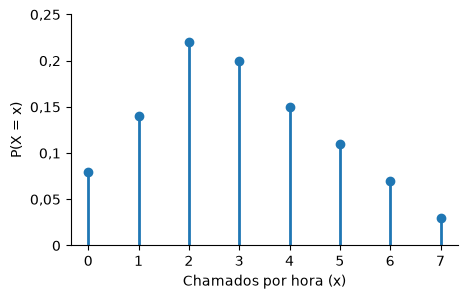

In [10]:
# Distribuição de probabilidades do número de chamados concluídos por hora
x_graf = np.arange(8)
p_graf = np.array([8, 14, 22, 20, 15, 11, 7, 3]) / 100
fig, ax = plt.subplots(figsize=(5, 3))
ax.vlines(x_graf, 0, p_graf, color="tab:blue", lw=2)
ax.plot(x_graf, p_graf, "o", color="tab:blue")
ax.set_xlabel("Chamados por hora (x)")
ax.set_ylabel("P(X = x)")
ax.set_ylim(0, 0.25)
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

In [27]:
X = [0, 1, 2, 3, 4, 5, 6, 7]
Freq = [8, 14, 22, 20, 15, 11, 7, 3]
Distr_P = []
for i in Freq:
    Distr_P = Distr_P + [i/sum(Freq)]
print(Distr_P)

[0.08, 0.14, 0.22, 0.2, 0.15, 0.11, 0.07, 0.03]


### Função de distribuição acumulada:

Definição: a função de distribuição acumulada (f.d.a.) de uma variável aleatória X é a probabilidade de X assumir um valor menor ou igual a x:

    F(x) = P(X <= x)

#### Exemplo - Continuação

Acumulando as probabilidades da distribuição do número de chamados por hora:

    P(X<=0) = P(X=0) = 0,08
    P(X<=1) = P(X<=0) + P(X=1) = 0,08+0,14 = 0,22
    P(X<=2) = P(X<=1) + P(X=2) = 0,22+0,22 = 0,44
    P(X<=3) = P(X<=2) + P(X=3) = 0,44+0,20 = 0,64
    P(X<=4) = P(X<=3) + P(X=4) = 0,64+0,15 = 0,79
    P(X<=5) = P(X<=4) + P(X=5) = 0,79+0,11 = 0,9
    P(X<=6) = P(X<=5) + P(X=6) = 0,9+0,07 = 0,97
    P(X<=7) = P(X<=6) + P(X=7) = 0,97+0,03 = 1

| Intervalo de $x$ | $F(x)$ |
|---|---|
| $x < 0$ | 0 |
| $0 \le x < 1$ | 0,08 |
| $1 \le x < 2$ | 0,22 |
| $2 \le x < 3$ | 0,44 |
| $3 \le x < 4$ | 0,64 |
| $4 \le x < 5$ | 0,79 |
| $5 \le x < 6$ | 0,9 |
| $6 \le x < 7$ | 0,97 |
| $x \ge 7$ | 1 |

### Tendência central e variabilidade para V.A discretas:

A média (valor esperado, ou esperança) de uma variável aleatória discreta é a média ponderada dos seus valores, com as probabilidades como pesos:

$$\mu = E(X) = \sum_{i} x_i \cdot P(X = x_i)$$

Ou seja, multiplica-se cada valor de x pela sua probabilidade e somam-se os produtos.

A variância de uma variável aleatória discreta pode ser obtida por:

$$\sigma^2 = E(X^2) - \mu^2, \quad \text{onde} \quad E(X^2) = \sum_{i} x_i^2 \cdot P(X = x_i)$$

O desvio padrão é obtido pela raiz quadrada da variância :

$$\sigma = \sqrt{\sigma^2}$$

#### Exemplo - Continuação
Calcule a média e o desvio padrão do número de chamados concluídos por hora, usando a distribuição obtida acima:

| $x$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| $P(X = x)$ | 0,08 | 0,14 | 0,22 | 0,20 | 0,15 | 0,11 | 0,07 | 0,03 |

Respostas: média 2,96; variância 3,1984; desvio padrão ≈ 1,7884.

In [28]:
#Distribuição de probabilidade a partir da Frequência

X = [0, 1, 2, 3, 4, 5, 6, 7]
Freq = [8, 14, 22, 20, 15, 11, 7, 3]
Distr_P = []
for i in Freq:
    Distr_P = Distr_P + [i/sum(Freq)]
print(Distr_P)

[0.08, 0.14, 0.22, 0.2, 0.15, 0.11, 0.07, 0.03]


In [50]:
#Média da probabilidade ou Esperança matemática

Media_P = 0
for i,j in enumerate(Distr_P):
    Media_P = Media_P + X[i] * j
print(Media_P)

2.96


In [51]:
#Esperança de X²

E_X_2 = 0
for i,j in enumerate(Distr_P):
    E_X_2 = E_X_2 + (X[i]**2) * j
print(E_X_2)

11.960000000000003


In [52]:
#Variância de Desvio padrão da probabilidade

Variancia_P = E_X_2 - (Media_P**2)
print(Variancia_P)
Desvio_P_P = Variancia_P**0.5
print(Desvio_P_P)

3.198400000000003
1.7884071124886534


### Propriedades da Média

**Propriedade 1:** se $X$ assume sempre o mesmo valor constante $c$, então $E(X) = c$.

**Propriedade 2:** multiplicar uma variável aleatória $X$ por uma constante $c$ multiplica a média pela mesma constante: $E(cX) = c \cdot E(X)$.

**Propriedade 3:** para quaisquer variáveis aleatórias $X$ e $Y$, a média da soma é a soma das médias: $E(X + Y) = E(X) + E(Y)$.

- a) Consequência para transformações lineares: se $Y = aX + b$, com $a$ e $b$ constantes, então $E(Y) = a \cdot E(X) + b$. Isso só vale para funções lineares; para uma função qualquer $g$, em geral $E(g(X)) \ne g(E(X))$.
- b) O resultado se estende a $n$ variáveis: $E(X_1 + X_2 + \cdots + X_n) = E(X_1) + E(X_2) + \cdots + E(X_n)$.

### Propriedades da Variância

- **Propriedade 1:** somar uma constante $c$ desloca os valores, mas não muda a dispersão: $\text{Var}(X + c) = \text{Var}(X)$.
- **Propriedade 2:** multiplicar por uma constante $c$ multiplica a variância pelo quadrado dela: $\text{Var}(cX) = c^2 \cdot \text{Var}(X)$.
- **Propriedade 3:** se $X$ e $Y$ são independentes, $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y)$.

**Observação:** ao contrário da média, a variância não é linear e, em geral, não é aditiva: a soma das variâncias vale, por exemplo, quando $X$ e $Y$ são independentes (basta que não sejam correlacionadas). Numa transformação linear, a constante somada desaparece e o coeficiente entra ao quadrado: $\text{Var}(aX + b) = a^2 \cdot \text{Var}(X)$, e não $a \cdot \text{Var}(X) + b$.

## Variáveis aleatórias contínuas

Uma variável aleatória é contínua quando pode assumir qualquer valor de um intervalo da reta real (tempos, distâncias, pesos...), de modo que seus valores não podem ser listados um a um.

### Função densidade de probabilidade:

Uma variável aleatória X é contínua quando existe uma função f(x), chamada função densidade de probabilidade (f.d.p.) de X, com as propriedades:

- a) $f(x) \ge 0$ para todo $x$;
- b) a área total sob $f(x)$ é igual a 1, ou seja, $\int_{-\infty}^{+\infty} f(x) dx = 1$;
- c) para quaisquer $a$ e $b$ com $-\infty < a < b < +\infty$, vale $P(a \le X \le b) = \int_{a}^{b} f(x) dx$.

Da propriedade c) segue que um valor isolado tem probabilidade zero, pois a integral de um ponto até ele mesmo é nula:

$$P(X = x_0) = \int_{x_0}^{x_0} f(x) dx = 0$$

Por isso, ao contrário do caso discreto, incluir ou não os extremos de um intervalo não altera a probabilidade:

$$P(a < X < b) = P(a \le X < b) = P(a < X \le b) = P(a \le X \le b)$$

Atenção: f(x) não é uma probabilidade. P(X = 2) = 0, mas f(2) pode ser diferente de zero (e pode até ser maior que 1). Probabilidades aparecem apenas como áreas, isto é, integrando f entre dois limites.

#### Exemplo:
Considere a função descrita a seguir:

$$f(x) = \frac{x - 3}{2}, \quad 3 \le x \le 5$$

e $f(x) = 0$ para qualquer outro valor de $x$.

- a) Verifique se a função acima é uma função densidade de probabilidade (f.d.p.).

1º passo: Verificar se f(x) > 0. 
Construindo o gráfico da função f(x) verificamos que ela é positiva em todo o domínio:

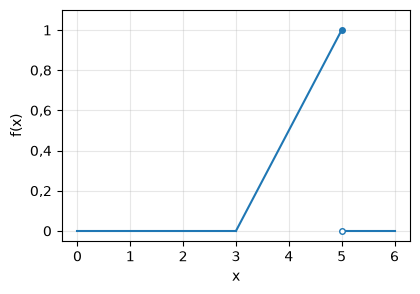

In [11]:
# Gráfico de f(x) = (x - 3)/2 para 3 <= x <= 5 (e zero fora desse intervalo)
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot([0, 3], [0, 0], color="tab:blue")
ax.plot([3, 5], [0, 1], color="tab:blue")
ax.plot([5, 6], [0, 0], color="tab:blue")
ax.plot(5, 1, "o", color="tab:blue", ms=4)
ax.plot(5, 0, "o", mfc="white", color="tab:blue", ms=4)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_ylim(-0.05, 1.1)
ax.grid(alpha=0.3)
virgula(ax)
plt.show()

In [78]:
#Definição da função e teste de um valor conhecido
def funcao(x):
    if x<=3 or x>=5:
        return 0
    else:
        return (x-3)/2
    
funcao(4.999)

0.9994999999999998

In [103]:
#Declaração manual de valores para a V.A. contínua e aplicação na função para visualização
X = [2, 3, 3.1, 3.5, 4, 4.5, 4.9, 5, 6]
for k in X:
    print("f({0})={1:8.4f}" .format(k,funcao(k)))

f(2)=  0.0000
f(3)=  0.0000
f(3.1)=  0.0500
f(3.5)=  0.2500
f(4)=  0.5000
f(4.5)=  0.7500
f(4.9)=  0.9500
f(5)=  0.0000
f(6)=  0.0000


In [77]:
#Declaração automática de valores para a V.A. contínua e aplicação na função para visualização
import numpy as np
X = np.arange(2, 6, 0.5)
for k in X:
    print("f({0})={1:8.4f}" .format(k,funcao(k)))

f(2.0)=  0.0000
f(2.5)=  0.0000
f(3.0)=  0.0000
f(3.5)=  0.2500
f(4.0)=  0.5000
f(4.5)=  0.7500
f(5.0)=  0.0000
f(5.5)=  0.0000


In [100]:
#Verifica se a função definida é positiva para todo x. 
#Obs: definir os limites e o passo do 'arange' para avaliar toda a função.
atende_cond_a = True
for k in np.arange(0, 6, 0.1):
    if funcao(k)>=0:
        next
    else:
        atende_cond_a = False

if atende_cond_a == True:
    print("f(x) atende a condição (a) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (a) para ser uma função densidade de probabilidade")

f(x) atende a condição (a) para ser uma função densidade de probabilidade


2º passo: Verificar se a área sob a curva da função f(x), em seu domínio, é igual a 1.
Por meio do cálculo da área da função f(x) temos que:

Uma primitiva de $f$ em $[3, 5]$ é $F(x) = \dfrac{x^2}{4} - \dfrac{3x}{2}$. Assim:

$$\int_{3}^{5} \frac{x - 3}{2} dx = F(5) - F(3) = \left(\frac{5^2}{4} - \frac{3 \cdot 5}{2}\right) - \left(\frac{3^2}{4} - \frac{3 \cdot 3}{2}\right) = (-1{,}25) - (-2{,}25) = 1$$

Dessa maneira podemos dizer que a função f(x) descrita no problema é uma função densidade de probabilidade (f.d.p.).

In [81]:
#Integral da função definida com os limites mínimo e máximo definidos
from scipy.integrate import quad
Integral = quad(funcao, 3, 5)
Integral[0]

1.0

In [84]:
#Integral da função definida com os limites infinitos
from scipy.integrate import quad
Integral = quad(funcao, -np.inf, np.inf)
Integral[0]

0.999999999999988

In [88]:
#Verifica se a Integral é aproximadamente 1 considerando o erro de cálculo da integral.
if abs(1-Integral[0]) <= Integral[1]:
    print("f(x) atende a condição (b) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (b) para ser uma função densidade de probabilidade")

f(x) atende a condição (b) para ser uma função densidade de probabilidade


- b) Se a função for uma fdp, calcule P(3,3<X<4).

Com a mesma primitiva $F(x) = \dfrac{x^2}{4} - \dfrac{3x}{2}$:

$$P(3{,}3 \le X < 4) = \int_{3{,}3}^{4} \frac{x - 3}{2} dx = F(4) - F(3{,}3) = \left(\frac{4^2}{4} - \frac{3 \cdot 4}{2}\right) - \left(\frac{3{,}3^2}{4} - \frac{3 \cdot 3{,}3}{2}\right) = (-2) - (-2{,}2275) = 0{,}2275$$

In [101]:
#Integral da função definida com os limites definidos
from scipy.integrate import quad
Integral = quad(funcao, 3.3, 4)
Integral[0]

0.22749999999999998

### Tendência central e variabilidade para V.A contínuas:

No caso contínuo a soma ponderada vira uma integral: a média de X, com densidade f(x), é

$$E(X) = \mu = \int_{-\infty}^{+\infty} x f(x) dx$$

A variância mede a dispersão em torno de μ:

$$\text{Var}(X) = \int_{-\infty}^{+\infty} (x - \mu)^2 f(x) dx$$

Na prática costuma ser mais fácil usar a forma equivalente:

$$\text{Var}(X) = E(X^2) - \mu^2$$

onde E(X²) é calculado por:

$$E(X^2) = \int_{-\infty}^{+\infty} x^2 f(x) dx$$

O desvio padrão é a raiz quadrada da variância e fica na mesma unidade de X.

#### Exemplo:
Em uma linha de montagem, o tempo T (em minutos) que um operador leva para montar um kit é modelado como uma variável aleatória contínua com a seguinte função densidade de probabilidade (modelo ilustrativo):

- $f(t) = \dfrac{t - 4}{40}$, se $8 \le t < 10$;
- $f(t) = \dfrac{3}{20}$, se $10 \le t \le 15$;
- $f(t) = 0$, caso contrário.

- a) Calcule o tempo médio de montagem, em minutos.

$$E(T) = \int_{8}^{10} t \cdot \frac{t - 4}{40} dt + \int_{10}^{15} t \cdot \frac{3}{20} dt$$

As primitivas são $\dfrac{t^3}{120} - \dfrac{t^2}{20}$ (primeira integral) e $\dfrac{3t^2}{40}$ (segunda). Avaliando nos limites:

$$E(T) = 2{,}2667 + 9{,}375 = 11{,}6417 \text{ minutos}$$

    - Verificando se a função é uma função densidade de probabilidade:

In [119]:
#Definição da função
def funcao(t):
    if t>=8 and t<10:
        return (t-4)/40
    elif t>=10 and t<=15:
        return 3/20
    else:
        return 0
    
funcao(14.99)

0.15

In [120]:
#Declaração automática de valores para a V.A. contínua e aplicação na função para visualização
import numpy as np
X = np.arange(7, 16, 0.5)
for k in X:
    print("f({0})={1:8.4f}" .format(k,funcao(k)))

f(7.0)=  0.0000
f(7.5)=  0.0000
f(8.0)=  0.1000
f(8.5)=  0.1125
f(9.0)=  0.1250
f(9.5)=  0.1375
f(10.0)=  0.1500
f(10.5)=  0.1500
f(11.0)=  0.1500
f(11.5)=  0.1500
f(12.0)=  0.1500
f(12.5)=  0.1500
f(13.0)=  0.1500
f(13.5)=  0.1500
f(14.0)=  0.1500
f(14.5)=  0.1500
f(15.0)=  0.1500
f(15.5)=  0.0000


In [121]:
#Verifica se a função definida é positiva para todo x. 
#Obs: definir os limites e o passo do 'arange' para avaliar toda a função!
atende_cond_a = True
for k in np.arange(7, 16, 0.1):
    if funcao(k)>=0:
        next
    else:
        atende_cond_a = False

if atende_cond_a == True:
    print("f(x) atende a condição (a) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (a) para ser uma função densidade de probabilidade")

f(x) atende a condição (a) para ser uma função densidade de probabilidade


In [151]:
#Integral da função definida com os limites infinitos
from scipy.integrate import quad
Integral = quad(funcao, -np.inf, np.inf)
Integral[0]

1.0000000001427456

In [123]:
#Verifica se a Integral é aproximadamente 1 considerando o erro de cálculo da integral.
if abs(1-Integral[0]) <= Integral[1]:
    print("f(x) atende a condição (b) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (b) para ser uma função densidade de probabilidade")
    print(Integral)
    print(1-Integral[0])

f(x) atende a condição (b) para ser uma função densidade de probabilidade


    - Definindo o integrando como x.f(x) para cálculo da média

In [134]:
#Integral de xf(x) calculando a média parcial do limite 'a' até 'b'
def integrando(t):
    return t*funcao(t)

a=8
b=10

from scipy.integrate import quad
Integral_parcial_1 = quad(integrando, a, b)
Integral_parcial_1[0]

2.2666666666666666

In [132]:
#Integral de xf(x) dx calculando a média parcial do limite 'a' até 'b'
def integrando(t):
    return t*funcao(t)

a=10
b=15

from scipy.integrate import quad
Integral_parcial_2 = quad(integrando, a, b)
Integral_parcial_2[0]

9.375000000000002

In [141]:
#Cálculo da média através da soma das médias parciais.
Media_Pc = Integral_parcial_1[0] + Integral_parcial_2[0]
Media_Pc

11.64166666666667

- b) Calcule o desvio padrão do tempo de montagem, em minutos.

Primeiramente vamos calcular o E(T²):

$$E(T^2) = \int_{8}^{10} t^2 \cdot \frac{t - 4}{40} dt + \int_{10}^{15} t^2 \cdot \frac{3}{20} dt$$

As primitivas são $\dfrac{t^4}{160} - \dfrac{t^3}{30}$ e $\dfrac{t^3}{20}$. Avaliando nos limites:

$$E(T^2) = 20{,}6333 + 118{,}75 = 139{,}3833$$

In [139]:
#Integral de x²f(x) dx calculando a média parcial ao quadrado do limite 'a' até 'b'
def integrando_2(t):
    return (t**2)*funcao(t)

a=8
b=10

from scipy.integrate import quad
Integral_parcial_2_1 = quad(integrando_2, a, b)
Integral_parcial_2_1[0]

20.633333333333333

In [138]:
#Integral de x²f(x) dx calculando a média parcial ao quadrado do limite 'a' até 'b'
def integrando_2(t):
    return (t**2)*funcao(t)

a=10
b=15

from scipy.integrate import quad
Integral_parcial_2_2 = quad(integrando_2, a, b)
Integral_parcial_2_2[0]

118.75

In [142]:
#Cálculo da média ao quadrado através da soma das médias parciais ao quadrado.
Media_Pc_2 = Integral_parcial_2_1[0] + Integral_parcial_2_2[0]
Media_Pc_2

139.38333333333333

Agora calcularemos a variância de T:

$$\text{Var}(T) = E(T^2) - \mu^2 = \frac{8363}{60} - \left(\frac{1397}{120}\right)^2 = \frac{55511}{14400} \approx 3{,}8549$$

(As frações são os valores exatos de $E(T^2) \approx 139{,}3833$ e $\mu \approx 11{,}6417$; arredondar $\mu$ antes de elevar ao quadrado muda a última casa decimal.)

In [143]:
Variancia_Pc = Media_Pc_2 - (Media_Pc**2)
Variancia_Pc

3.854930555555484

Por fim, calculamos o desvio padrão:

$$\sigma = \sqrt{\text{Var}(T)} = \sqrt{3{,}8549} \approx 1{,}9634 \text{ minuto}$$

In [145]:
Desvio_P_Pc = Variancia_Pc**0.5
Desvio_P_Pc

1.9633977069242705

- c) Calcule a probabilidade de uma montagem levar entre 9 e 12 minutos.

$$P(9 < T < 12) = \int_{9}^{10} \frac{t - 4}{40} dt + \int_{10}^{12} \frac{3}{20} dt = 0{,}1375 + 0{,}3 = 0{,}4375$$

In [148]:
#Integral diretamente da função definida com os limites de acordo com enunciado.
from scipy.integrate import quad
Integral_1 = quad(funcao, 9, 12)
Integral_1[0]

0.43749999999999994

- d) Sabendo que uma montagem já passou de 8 minutos, qual a probabilidade de que termine em menos de 14 minutos? É uma probabilidade condicional com variável contínua:

$$P(T < 14 \mid T > 8) = \frac{P(T < 14 \text{ e } T > 8)}{P(T > 8)} = \frac{P(8 < T < 14)}{P(T > 8)}$$

$$P(T < 14 \mid T > 8) = \frac{\int_{8}^{10} \frac{t - 4}{40} dt + \int_{10}^{14} \frac{3}{20} dt}{\int_{8}^{10} \frac{t - 4}{40} dt + \int_{10}^{15} \frac{3}{20} dt} = \frac{0{,}25 + 0{,}6}{0{,}25 + 0{,}75} = 0{,}85$$

In [149]:
#Integral diretamente da função definida com os limites de acordo com enunciado.
from scipy.integrate import quad
Integral_2_1 = quad(funcao, 8, 14)
Integral_2_2 = quad(funcao, 8, np.inf)
Integral_2 = Integral_2_1[0] / Integral_2_2[0]
Integral_2

0.8499999999999966

## Modelos probabilísticos para V.A. discretas

Alguns modelos de probabilidade para variáveis aleatórias discretas que aparecem com frequência:
- a) Uniforme discreta
- b) Bernoulli
- c) Geométrica
- d) Pascal ou Binomial negativa
- e) Hipergeométrica
- f) Polinomial ou multinomial
- g) Binomial
- h) Poisson

### Distribuição Binomial

Considere n repetições independentes de um experimento com apenas dois resultados, "sucesso" e "fracasso", em que a probabilidade de sucesso, p, é a mesma em todas as repetições (e a de fracasso é q = 1 − p).

Definição: se X é o número de sucessos nas n repetições, X pode valer 0, 1, 2, ..., n e dizemos que X tem distribuição binomial com parâmetros n e p, X ~ B(n; p).
Nesse caso, a média e a variância de X são:
- a) Média de X: E(X) = np.
- b) Variância de X: σ² = npq, onde q = 1 - p.

A função de probabilidade da variável aleatória X ~ B(n; p) é dada por:

$$P(X = x) = \binom{n}{x} p^x (1 - p)^{n - x}, \quad x = 0, 1, 2, \ldots, n$$

Em que o coeficiente binomial (número de combinações de n elementos tomados x a x) é:

$$\binom{n}{x} = \frac{n!}{x! \cdot (n - x)!}$$

#### Exemplo:

Uma fábrica de chips sabe que 4% das unidades produzidas saem com defeito. Um inspetor escolhe 12 chips ao acaso.

Observe que:
- cada chip tem só dois resultados possíveis (defeituoso ou não);
- o número de repetições é fixo (12 chips) e as escolhas são independentes;
- a probabilidade de defeito é a mesma para todos os chips, p = 0,04, e a de não defeito é q = 1 - p = 0,96.

Portanto, o modelo binomial é adequado: X ~ B(12; 0,04).

- a) Identifique a variável aleatória estudada. Quais valores ela pode assumir?

    X: número de chips defeituosos na amostra;

    x= 0, 1, 2,..., 12.

- b) Calcule o número médio de chips defeituosos e, também, o desvio padrão.

    Média: E(X) = np = 12 . 0,04 = 0,48;

    Variância: σ² = npq = 12 . 0,04 . 0,96 = 0,4608;

    Desvio padrão: σ = √𝜎² = 0,6788.

In [153]:
#Definindo n e p
n = 12
p = 0.04
q = 1 - p
q

0.96

In [159]:
#Calculando a Média de X ~ B(n;p)
Media_B = n*p
print("Média (E(X)) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Media_B))

Média (E(X)) de X~B(12;0.04) =   0.4800


In [158]:
#Calculando Variância e Desvio Padrão de X ~ B(n;p)
Variancia_B = n*p*q
print("Variância (σ²) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Variancia_B))
Desvio_P_B = Variancia_B**0.5
print("Desvio padrão (σ) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Desvio_P_B))

Variância (σ²) de X~B(12;0.04) =   0.4608
Desvio padrão (σ) de X~B(12;0.04) =   0.6788


- c) Qual será a probabilidade de que:
        Exatamente 7 sejam defeituosos?

$$P(X = 7) = \binom{12}{7} \cdot 0{,}04^7 \cdot 0{,}96^5 = 792 \cdot 0{,}04^7 \cdot 0{,}96^5 \approx 1{,}0580 \times 10^{-7}$$

In [161]:
#Calculando coeficiente binominal para x de acordo com enunciado:
from math import factorial

x = 7

Coeficiente_B = factorial(n) / (factorial(x) * factorial(n-x))
Coeficiente_B

792.0

In [162]:
#Calculando a Probabilidade de acordo com a fómula da Distribuição Binominal
Prob_B = Coeficiente_B * (p**x) * (q**(n-x))
Prob_B

1.0580380491762894e-07

- d) Qual será a probabilidade de que:
        No máximo 8 sejam defeituosos?

$$P(X \le 8) = 1 - P(X > 8) = 1 - [P(X = 9) + P(X = 10) + P(X = 11) + P(X = 12)]$$

$$P(X = 9) = \binom{12}{9} \cdot 0{,}04^9 \cdot 0{,}96^3 \approx 5{,}1024 \times 10^{-11}$$

$$P(X = 10) \approx 6{,}3780 \times 10^{-13} \qquad P(X = 11) \approx 4{,}8318 \times 10^{-15} \qquad P(X = 12) \approx 1{,}6777 \times 10^{-17}$$

$$P(X \le 8) \approx 1 - 5{,}1667 \times 10^{-11} \approx 1$$

    Calculando através do inverso de Probabilidade, conforme resposta acima:

In [169]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

# P(X <= 8) = 1 - P(X > 8)
# X = [0, 1, 2,...,12]
# P(X > 8) = P(X = 9) + P(X = 10) + P(X = 11) + P(X = 12), portanto,
x = [9, 10, 11, 12]

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

Coenficiente (X = 9) = 220.0
Coenficiente (X = 10) = 66.0
Coenficiente (X = 11) = 12.0
Coenficiente (X = 12) = 1.0


In [173]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_B))

P(X = 9) = 5.1024211476480005e-11
P(X = 10) = 6.378026434560001e-13
P(X = 11) = 4.831838208000001e-15
P(X = 12) = 1.6777216000000005e-17


A soma das probabilidade é: 5.166686273536e-11
O inverso da soma das probabilidade é: 0.9999999999483331


    Calculando diretamente a Probabilidade socilitada como é mais intuitivo:

In [177]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

# P(X <= 8)
# portanto,
x = np.arange(0, 9 , 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [0 1 2 3 4 5 6 7 8]
Coenficiente (X = 0) = 1.0
Coenficiente (X = 1) = 12.0
Coenficiente (X = 2) = 66.0
Coenficiente (X = 3) = 220.0
Coenficiente (X = 4) = 495.0
Coenficiente (X = 5) = 792.0
Coenficiente (X = 6) = 924.0
Coenficiente (X = 7) = 792.0
Coenficiente (X = 8) = 495.0


In [178]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 0) = 0.6127097573297671
P(X = 1) = 0.3063548786648836
P(X = 2) = 0.07020632636070248
P(X = 3) = 0.00975087866120868
P(X = 4) = 0.0009141448744883137
P(X = 5) = 6.0942991632554255e-05
P(X = 6) = 2.9625065376936098e-06
P(X = 7) = 1.0580380491762894e-07
P(X = 8) = 2.75530741972992e-09


A soma das probabilidade é: 0.9999999999483326


- e) Qual será a probabilidade de que:
        Mais de 9 não sejam defeituosos?

Como cada amostra tem 12 chips, "mais de 9 não defeituosos" (10, 11 ou 12) é o mesmo evento que "menos de 3 defeituosos" (2, 1 ou 0):

| Chips não defeituosos | Chips defeituosos |
|---|---|
| 10 | 2 |
| 11 | 1 |
| 12 | 0 |

Logo, basta calcular a probabilidade de menos de 3 chips defeituosos na amostra:

$$P(X < 3) = P(X \le 2) = P(X = 0) + P(X = 1) + P(X = 2) \approx 0{,}61271 + 0{,}30635 + 0{,}07021 \approx 0{,}9893$$

In [179]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo n e p
n = 12
p = 0.04
q = 1 - p

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X <= 2) portanto,
x = np.arange(0, 3 , 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [0 1 2]
Coenficiente (X = 0) = 1.0
Coenficiente (X = 1) = 12.0
Coenficiente (X = 2) = 66.0


In [180]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 0) = 0.6127097573297671
P(X = 1) = 0.3063548786648836
P(X = 2) = 0.07020632636070248


A soma das probabilidade é: 0.9892709623553531


#### Exercício 1:

Uma cooperativa sabe, pelo histórico, que cada lote de sementes tem 15% de chance de apresentar taxa de germinação abaixo do padrão, de forma independente entre lotes. Para os próximos 20 lotes, encontre a probabilidade de que:

- a) Exatamente 2 lotes fiquem abaixo do padrão. R: 0,2293

In [182]:
#Definindo n e p
n = 20
p = 0.15
q = 1 - p
q

0.85

In [183]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 2) portanto,
x = [2]

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [2]
Coenficiente (X = 2) = 190.0


In [184]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 2) = 0.22933840191875263


A soma das probabilidade é: 0.22933840191875263


- b) Pelo menos 4 lotes fiquem abaixo do padrão. R: 0,3523

In [185]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 4) portanto,
x = np.arange(4, 21 , 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Coenficiente (X = 4) = 4845.0
Coenficiente (X = 5) = 15504.0
Coenficiente (X = 6) = 38760.0
Coenficiente (X = 7) = 77520.0
Coenficiente (X = 8) = 125970.0
Coenficiente (X = 9) = 167960.0
Coenficiente (X = 10) = 184756.0
Coenficiente (X = 11) = 167960.0
Coenficiente (X = 12) = 125970.0
Coenficiente (X = 13) = 77520.0
Coenficiente (X = 14) = 38760.0
Coenficiente (X = 15) = 15504.0
Coenficiente (X = 16) = 4845.0
Coenficiente (X = 17) = 1140.0
Coenficiente (X = 18) = 190.0
Coenficiente (X = 19) = 20.0
Coenficiente (X = 20) = 1.0


In [186]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 4) = 0.18212167211195063
P(X = 5) = 0.10284517954557212
P(X = 6) = 0.04537287332892888
P(X = 7) = 0.016013955292563133
P(X = 8) = 0.004592237179485014
P(X = 9) = 0.0010805263951729448
P(X = 10) = 0.00020974924141592456
P(X = 11) = 3.364961092234084e-05
P(X = 12) = 4.4536249750157e-06
P(X = 13) = 4.836515809971799e-07
P(X = 14) = 4.267513949975118e-08
P(X = 15) = 3.0123627882177305e-09
P(X = 16) = 1.6612294787965423e-10
P(X = 17) = 6.8978386662832204e-12
P(X = 18) = 2.0287760783185943e-13
P(X = 19) = 3.768624294090268e-15
P(X = 20) = 3.3252567300796485e-17


A soma das probabilidade é: 0.3522748258432968


- c) De 3 a 7 lotes fiquem abaixo do padrão. R: 0,5892

In [187]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 3) - P(X > 7) portanto,
x = np.arange(3, 8, 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [3 4 5 6 7]
Coenficiente (X = 3) = 1140.0
Coenficiente (X = 4) = 4845.0
Coenficiente (X = 5) = 15504.0
Coenficiente (X = 6) = 38760.0
Coenficiente (X = 7) = 77520.0


In [188]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 3) = 0.24282889614926745
P(X = 4) = 0.18212167211195063
P(X = 5) = 0.10284517954557212
P(X = 6) = 0.04537287332892888
P(X = 7) = 0.016013955292563133


A soma das probabilidade é: 0.5891825764282822


- d) O número médio e a variância de lotes abaixo do padrão. R: 3 e 2,55.

In [189]:
#Definindo n e p
n = 20
p = 0.15
q = 1 - p
q

0.85

In [190]:
#Calculando a Média de X ~ B(n;p)
Media_B = n*p
print("Média (E(X)) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Media_B))

Média (E(X)) de X~B(20;0.15) =   3.0000


In [191]:
#Calculando Variância e Desvio Padrão de X ~ B(n;p)
Variancia_B = n*p*q
print("Variância (σ²) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Variancia_B))
Desvio_P_B = Variancia_B**0.5
print("Desvio padrão (σ) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Desvio_P_B))

Variância (σ²) de X~B(20;0.15) =   2.5500
Desvio padrão (σ) de X~B(20;0.15) =   1.5969


#### Exercício 2:

Em uma loja, 30% dos clientes que entram fazem alguma compra. Considerando 5 clientes escolhidos ao acaso, qual é a probabilidade de que no máximo 2 deles comprem? Resposta: 0,8369

In [192]:
#Definindo n e p
n = 5
p = 0.3
q = 1 - p
q

0.7

In [193]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X <= 2) portanto,
x = np.arange(0, 3, 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [0 1 2]
Coenficiente (X = 0) = 1.0
Coenficiente (X = 1) = 5.0
Coenficiente (X = 2) = 10.0


In [194]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 0) = 0.16806999999999994
P(X = 1) = 0.3601499999999999
P(X = 2) = 0.3086999999999999


A soma das probabilidade é: 0.8369199999999999


#### Exercício 3:

Um fornecedor de lâmpadas LED garante que cada caixa com 25 unidades tem no máximo 1 lâmpada defeituosa. Se o processo de fabricação gera 3% de lâmpadas defeituosas, qual é a probabilidade de uma caixa não cumprir a garantia?
Resposta: 0,1720

In [195]:
#Definindo n e p
n = 25
p = 0.03
q = 1 - p
q

0.97

In [200]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X > 1) portanto,
x = np.arange(2, 26, 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25]
Coenficiente (X = 2) = 300.0
Coenficiente (X = 3) = 2300.0
Coenficiente (X = 4) = 12650.0
Coenficiente (X = 5) = 53130.0
Coenficiente (X = 6) = 177100.0
Coenficiente (X = 7) = 480700.0
Coenficiente (X = 8) = 1081575.0
Coenficiente (X = 9) = 2042975.0
Coenficiente (X = 10) = 3268760.0
Coenficiente (X = 11) = 4457400.0
Coenficiente (X = 12) = 5200300.0
Coenficiente (X = 13) = 5200300.0
Coenficiente (X = 14) = 4457400.0
Coenficiente (X = 15) = 3268760.0
Coenficiente (X = 16) = 2042975.0
Coenficiente (X = 17) = 1081575.0
Coenficiente (X = 18) = 480700.0
Coenficiente (X = 19) = 177100.0
Coenficiente (X = 20) = 53130.0
Coenficiente (X = 21) = 12650.0
Coenficiente (X = 22) = 2300.0
Coenficiente (X = 23) = 300.0
Coenficiente (X = 24) = 25.0
Coenficiente (X = 25) = 1.0


In [201]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 2) = 0.13400273187233538
P(X = 3) = 0.0317738436398321
P(X = 4) = 0.005404829072754945
P(X = 5) = 0.000702070580584663
P(X = 6) = 7.237841036955288e-05
P(X = 7) = 6.075949029550094e-06
P(X = 8) = 4.2281088607693955e-07
P(X = 9) = 2.47002923137731e-08
P(X = 10) = 1.2222825062485656e-09
P(X = 11) = 5.154893419042686e-11
P(X = 12) = 1.860013089345299e-12
P(X = 13) = 5.752617802098862e-14
P(X = 14) = 1.5249944099820256e-15
P(X = 15) = 3.458750208206656e-17
P(X = 16) = 6.685728495244825e-19
P(X = 17) = 1.0946917487665871e-20
P(X = 18) = 1.5047309261396387e-22
P(X = 19) = 1.714560469285535e-24
P(X = 20) = 1.5908293013989502e-26
P(X = 21) = 1.1714501483055598e-28
P(X = 22) = 6.587348537800711e-31
P(X = 23) = 2.6573795087497263e-33
P(X = 24) = 6.848916259664245e-36
P(X = 25) = 8.472886094429992e-39


A soma das probabilidade é: 0.1719623783118351


### Distribuição Poisson (distribuição dos eventos raros)

Alguns exemplos de variáveis que contam ocorrências:

    X1 = número de mensagens que chegam a uma caixa de e-mail em uma hora;
    X2 = número de defeitos em um metro quadrado de tecido;
    X3 = número de clientes que entram em uma loja em 10 minutos;
    X4 = número de buracos em um quilômetro de estrada.

Em todos eles, X conta eventos que acontecem ao acaso ao longo de um meio contínuo (tempo, área, comprimento, volume) e pode valer x = 0, 1, 2, ... Quando os eventos ocorrem de forma independente e com taxa média constante, X segue a distribuição de Poisson, com função de probabilidade:

$$P(X = x) = \frac{e^{-\lambda} \lambda^x}{x!}, \quad x = 0, 1, 2, \ldots$$

O parâmetro λ > 0 é a taxa de ocorrência: o número médio de eventos no intervalo considerado. Notação: X ~ Po(λ).

Se X tiver distribuição de Poisson com parâmetro λ, então o valor esperado e a variância são:

$$E(X) = \lambda \qquad \text{Var}(X) = \lambda$$

#### Exemplo:
Uma loja virtual recebe, em média, quatro pedidos por minuto.
- a) Defina a variável aleatória.

        X: número de pedidos recebidos em um minuto.
        x: 0, 1, 2, ...
        X ~ Po(4)

- b) Calcule a probabilidade de que, em um intervalo de um minuto:

    i. Nenhum pedido seja recebido.

$$P(X = 0) = \frac{e^{-4} \cdot 4^0}{0!} \approx 0{,}0183$$

In [203]:
#Definindo a Média/Taxa de ocorrência do evento.
Media_Po = 4

In [205]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 0 ) portanto,
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))


X pode assumir os valores: [0]
P(X = 0) = 0.01831563888873418


A soma das probabilidade é: 0.01831563888873418


- b) Calcule a probabilidade de que, em um intervalo de um minuto:

    ii. Seja recebido, no máximo, um pedido.

$$P(X = 1) = \frac{e^{-4} \cdot 4^1}{1!} \approx 0{,}0733$$

$$P(X \le 1) = P(X = 0) + P(X = 1) \approx 0{,}0183 + 0{,}0733 = 0{,}0916$$

In [206]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X <= 1) portanto,
x = [0, 1]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))


X pode assumir os valores: [0, 1]
P(X = 0) = 0.01831563888873418
P(X = 1) = 0.07326255555493671


A soma das probabilidade é: 0.0915781944436709


- b) Calcule a probabilidade de que, em um intervalo de um minuto:

    iii. Sejam recebidos mais de dois pedidos.

$$P(X = 2) = \frac{e^{-4} \cdot 4^2}{2!} \approx 0{,}1465$$

$$P(X > 2) = 1 - P(X \le 2) = 1 - [P(X = 0) + P(X = 1) + P(X = 2)] \approx 1 - 0{,}2381 = 0{,}7619$$

In [207]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X > 2) porém cálculo com infinito complica,
# então,
# P(X > 2) = 1 - P(X <= 2) = 1 - [P(X=0) -  P(X=1) - P(X=2)]
x = np.arange(0, 3, 1)

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0 1 2]
P(X = 0) = 0.01831563888873418
P(X = 1) = 0.07326255555493671
P(X = 2) = 0.14652511110987343


A soma das probabilidade é: 0.2381033055535443
O inverso da soma das probabilidade é: 0.7618966944464557


- c) Em um intervalo de três minutos, qual é a probabilidade de que cheguem exatamente 15 pedidos?

Como o intervalo mudou, o parâmetro muda na mesma proporção: λ = 4 pedidos por minuto passa a ser λ = 12 pedidos a cada três minutos. Assim:

$$P(X = 15) = \frac{e^{-12} \cdot 12^{15}}{15!} \approx 0{,}0724$$

In [209]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o período de tempo do enunciado.
Tempo = 3 #minutos
Media_Po = 4*Tempo

In [210]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 15) portanto,
x = [15]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [15]
P(X = 15) = 0.07239112014663869


A soma das probabilidade é: 0.07239112014663869


#### Exercício 4:
Defeitos de pintura aparecem ao acaso na superfície de chapas metálicas. Suponha que o número de defeitos siga a distribuição de Poisson, com média de 1,8 defeito por metro quadrado.

- a) Determine a probabilidade de exatamente 2 defeitos em 1 m² de chapa. R: 0,2678

In [213]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 1 #metro²
Media_Po = 1.8*Comprimento

In [214]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 15) portanto,
x = [2]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [2]
P(X = 2) = 0.2677841989189702


A soma das probabilidade é: 0.2677841989189702


- b) Determine a probabilidade de existirem entre 2 e 4 defeitos em 1 m² de chapa. R: 0,1607

    Para variáveis aleatórias discretas, ou seja, que assumem somente valores inteiros, temos que ter muito cuidado visto que: A Probabilidade de 2 a 4 ocorrências corresponde a P(2<=X<=4) = P(X=2)+P(X=3)+P(X=4) porém, a probabilidade entre 2 e 4 ocorrências corresponde a P(2<X<4)=P(X=3). Em nosso dia-a-dia, temos o costume de dizer 'de 2 a 4' e 'entre 2 e 4' como sinônimos mas, matematicamente falando, são diferentes. Para variáveis aleatórias contínuas, pela maneira como as probabilidades são obtidas (por meio do cálculo da área), aí sim P(2<=X<=4) = P(2<X<4).

In [213]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 1 #metro²
Media_Po = 1.8*Comprimento

In [218]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# Pelo termo 'entre 2 e 4' não incluir os extremos, P(X = 3), portanto,
x = [3]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [3]
P(X = 3) = 0.16067051935138213


A soma das probabilidade é: 0.16067051935138213


- c) Determine a probabilidade de 8 defeitos em 4 m² de chapa. R: 0,1337

In [220]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 4 #metro²
Media_Po = 1.8*Comprimento

In [221]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 8) portanto,
x = [8]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [8]
P(X = 8) = 0.13372702354142837


A soma das probabilidade é: 0.13372702354142837


- d) Determine a probabilidade de existir, no mínimo, um defeito em 2 m² de chapa. R: 0,9727

In [222]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 2 #metro²
Media_Po = 1.8*Comprimento

In [223]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 1) e por ter infinito, usando o inverso,
# P(X >= 1)  = 1 - P(X < 1) = 1 - P(X=0), portanto,
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0]
P(X = 0) = 0.02732372244729256


A soma das probabilidade é: 0.02732372244729256
O inverso da soma das probabilidade é: 0.9726762775527075


#### Exercício 5:
Uma revisora encontra, em média, 0,2 erro de digitação por página nos textos de um autor; o número de erros segue a distribuição de Poisson.

- a) Qual é a probabilidade de haver dois erros em 1 página? R: 0,0164

In [225]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 1 #páginas
Media_Po = 0.2*Comprimento

In [226]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 2) portanto,
x = [2]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [2]
P(X = 2) = 0.016374615061559638


A soma das probabilidade é: 0.016374615061559638


- b) Qual é a probabilidade de haver um erro em 5 páginas? R: 0,3679

In [228]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 5 #páginas
Media_Po = 0.2*Comprimento

In [229]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 1) portanto,
x = [1]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [1]
P(X = 1) = 0.36787944117144233


A soma das probabilidade é: 0.36787944117144233


- c) Qual é a probabilidade de não haver erros em 10 páginas? R: 0,1353

In [231]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 10 #páginas
Media_Po = 0.2*Comprimento

In [232]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 0) portanto,
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [0]
P(X = 0) = 0.1353352832366127


A soma das probabilidade é: 0.1353352832366127


- d) Qual é a probabilidade de haver no mínimo dois erros em 5 páginas? R: 0,2642

In [238]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 5 #páginas
Media_Po = 0.2*Comprimento

In [249]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 2) e por envolver infinito, usando o inverso,
# P(X >= 2) = 1 - P(X < 2) = 1 - [P(X=0) + P(X=1)]
x = [0, 1]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))
    
print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0, 1]
P(X = 0) = 0.36787944117144233
P(X = 1) = 0.36787944117144233


A soma das probabilidade é: 0.7357588823428847
O inverso da soma das probabilidade é: 0.26424111765711533


#### Exercício 6:
O atendimento por chat de uma empresa recebe, no horário de pico, em média 8 mensagens por minuto. Para dimensionar a equipe, calcule as probabilidades a seguir:

- a) Qual é a probabilidade de nenhuma mensagem chegar em 15 segundos? R: 0,1353

In [250]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Tempo = 0.25 #minuto
Media_Po = 8*Tempo

In [251]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 0)
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))
    
print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [0]
P(X = 0) = 0.1353352832366127


A soma das probabilidade é: 0.1353352832366127


- b) Qual é a probabilidade de três ou mais mensagens chegarem em 15 segundos? R: 0,3233

In [250]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Tempo = 0.25 #minuto
Media_Po = 8*Tempo

In [252]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 3) e por envolver infinito, usando o inverso,
# P(X >= 3) = 1 - P(X < 3) = 1 - [P(X=0) + P(X=1) + P(X=2)]
x = [0, 1, 2]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))
    
print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0, 1, 2]
P(X = 0) = 0.1353352832366127
P(X = 1) = 0.2706705664732254
P(X = 2) = 0.2706705664732254


A soma das probabilidade é: 0.6766764161830635
O inverso da soma das probabilidade é: 0.3233235838169365


## Modelos probabilísticos para V.A. contínuas

Modelos de probabilidade contínuos de uso frequente:
- a) Uniforme
- b) Normal
- c) Exponencial
- d) Gama
- e) Weibull
- f) Beta
- g) Lognormal

### Distribuição Exponencial

A distribuição exponencial é usada para modelar tempos até a ocorrência de um evento, como a espera por atendimento, a duração de um componente eletrônico ou o intervalo entre chegadas. Definição: uma v. a. contínua X tem distribuição exponencial com parâmetro α quando sua f.d.p. é:

$$f(x) = \alpha e^{-\alpha x}, \quad x > 0 \text{ e } \alpha > 0$$

e $f(x) = 0$ para os demais valores de $x$.

A notação que utilizaremos para representar que uma v. a. contínua X tem distribuição exponencial é: X ~ Exp (α).

A média e a variância da distribuição exponencial são:

$$E(X) = \frac{1}{\alpha} \qquad \text{Var}(X) = \frac{1}{\alpha^2}$$

Apresentamos na figura abaixo o gráfico da distribuição exponencial para três valores diferentes para o parâmetro (α).

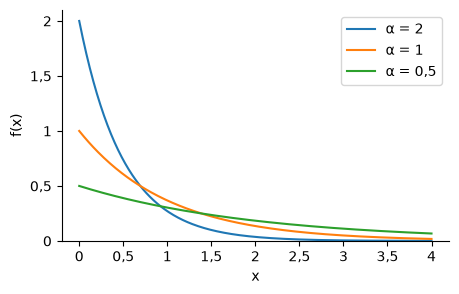

In [12]:
# Densidade exponencial f(x) = α·e^(-αx) para três valores de α
x_graf = np.linspace(0, 4, 300)
fig, ax = plt.subplots(figsize=(5, 3))
for alfa_graf in (2, 1, 0.5):
    ax.plot(x_graf, alfa_graf * np.exp(-alfa_graf * x_graf), label=f"α = {alfa_graf:g}".replace(".", ","))
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_ylim(bottom=0)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

Para qualquer intervalo de a até b, a probabilidade de uma exponencial é obtida integrando a densidade:

$$P(a \le X \le b) = \int_{a}^{b} \alpha e^{-\alpha x} dx = e^{-\alpha a} - e^{-\alpha b}$$

Como X é contínua, incluir ou não os extremos a e b não muda o resultado.

Em particular, com a = 0 ficam duas fórmulas práticas, uma para cada lado de t:

$$P(X > t) = e^{-\alpha t}$$

e, pelo complementar,

$$P(X \le t) = 1 - e^{-\alpha t}$$

#### Propriedade de falta de memória: 
Seja X exponencial com parâmetro α e sejam s, t > 0. Então:

$$P(X \ge t + s \mid X \ge s) = \frac{P(X \ge t + s \text{ e } X \ge s)}{P(X \ge s)} = \frac{P(X \ge t + s)}{P(X \ge s)}$$

Como $P(X \ge u) = \int_{u}^{+\infty} \alpha e^{-\alpha x} dx = e^{-\alpha u}$ para qualquer $u > 0$:

$$P(X \ge t + s \mid X \ge s) = \frac{e^{-\alpha (t + s)}}{e^{-\alpha s}} = e^{-\alpha t} = P(X \ge t)$$

Interpretação, pensando em X como a duração de um equipamento: se ele já funcionou s horas, a chance de durar mais t horas é a mesma de um equipamento novo durar t horas. O tempo já decorrido não influencia o que vem pela frente; só importa quanto tempo a mais se quer que ele dure.

#### Exemplo 1:
O tempo até a primeira falha de um modelo de SSD, em horas, é modelado por uma distribuição exponencial com parâmetro 1/5000.

- a) Calcule o tempo médio até a falha.

    X: tempo até a primeira falha de um SSD;
    X ~ Exp (1/5000).

$$E(X) = \frac{1}{\alpha} = \frac{1}{1/5000} = 5000 \text{ horas}$$

In [253]:
#Definindo o parâmentro alfa (α) e calculando a Média.
Alfa_Exp = 1/5000
Media_Exp = 1/Alfa_Exp
Media_Exp

5000.0

- b) Calcule a probabilidade de que um SSD funcione pelo menos 2500 horas sem falhar.

    A exponencial começa em zero e não tem limite superior; por isso calculamos pelo complementar:

$$P(X \ge 2500) = 1 - P(0 < X < 2500) = 1 - \left(e^{-0/5000} - e^{-2500/5000}\right) = e^{-0{,}5} \approx 0{,}6065$$

In [254]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α)
Alfa_Exp = 1/5000


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado

# P(X >= 2500), por envolver infinito, usando o complementar da probabilidade,
# P(X >= 2500) = 1 - P(0 < X < 2500), portanto
a_Exp = 0
b_Exp = 2500


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.3934693402873666
O inverso da probabilidade é: 0.6065306597126334


- c) O fabricante troca o SSD se ele falhar nas primeiras 40 horas. Qual é a probabilidade de haver troca?

$$P(X < 40) = P(0 < X < 40) = e^{-0/5000} - e^{-40/5000} = 1 - e^{-0{,}008} \approx 0{,}0080$$

In [255]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α)
Alfa_Exp = 1/5000


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado
# P(X < 40) = P(0 < X < 40), portanto
a_Exp = 0
b_Exp = 40


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.007968085162939342
O inverso da probabilidade é: 0.9920319148370607


- d) Um SSD já funciona há 5500 horas. Qual é a probabilidade de que chegue a pelo menos 8000 horas? Pela falta de memória da exponencial:

$$P(X \ge 8000 \mid X \ge 5500) = P(X \ge 2500) \approx 0{,}6065$$

In [257]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α), tempo estimado de duração (t+s) e tempo de uso (s)
Alfa_Exp = 1/5000
s_Exp = 5500
t_Exp = 8000 - s_Exp

#Definindo os limites inferior (a) e superior (b) de acordo com enunciado

# P(X >= 2500), por envolver infinito, usando o complementar da probabilidade,
# P(X >= 2500) = 1 - P(0 < X < 2500), portanto
a_Exp = 0
b_Exp = t_Exp


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.3934693402873666
O inverso da probabilidade é: 0.6065306597126334


#### Exercício 1:
A duração da bateria de um sensor sem fio segue, aproximadamente, uma distribuição exponencial com média de 1500 horas.

- a) Que porcentagem das baterias se esgota antes de 1500 horas? R: 0,6321

    Como 1500 horas é exatamente a média (1/α), a probabilidade pedida é P(X ≤ E(X)), que não depende de α:

$$P\left(X \le \frac{1}{\alpha}\right) = \int_{0}^{1/\alpha} \alpha e^{-\alpha x} dx = 1 - e^{-\alpha \cdot (1/\alpha)} = 1 - e^{-1} \approx 0{,}6321$$

Ou seja, qualquer que seja $\alpha$, cerca de 63,2% dos valores de uma exponencial ficam abaixo da média.

In [259]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α)
Media_Exp = 1500
Alfa_Exp = 1/Media_Exp


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado
# P(X < 1500) = P(0 < X < 1500), portanto
a_Exp = 0
b_Exp = 1500


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.6321205588285577
O inverso da probabilidade é: 0.36787944117144233


- b) Depois de quantas horas metade das baterias terá se esgotado? R: 1039,7208 horas

$$P(X > t) = e^{-\alpha t}$$

    Usando a fórmula acima (limite inferior a = 0), procuramos t tal que

    P(X <= t) = 0,50, ou seja, P(X > t) = 0,50

    e**(-t/1500) = 0,50

    Aplicando o logaritmo natural dos dois lados:

    -t/1500 = ln 0,50

    t = -1500 · ln 0,50 = 1500 · ln 2

In [261]:
#Calculando o tempo baseado na Probabilidade com a Distribuição Exponencial
from math import exp
from math import log

#Definindo o parâmetro alfa (α)
Media_Exp = 1500
Alfa_Exp = 1/Media_Exp


#Definindo a probabilidade
Prob_Exp = 0.5

#Calculando t em P(X > t) = Prob_Exp
t_Exp = -(log(Prob_Exp)/Alfa_Exp)
print("É provável que mais de {0}% falhará em {1} horas" .format(Prob_Exp*100,t_Exp))

É provável que mais de 50.0% falhará em 1039.720770839918 horas


#### Exercício 2:
Uma fábrica produz baterias por dois processos: 60% saem do processo A e o restante do processo B. A duração, em horas, segue uma exponencial com média 120 horas no processo A e 90 horas no processo B. Escolhendo uma bateria ao acaso, qual é a probabilidade de que ela dure mais de 100 horas? R: 0,3924

In [262]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α) e as Probabilidades de ocorrência dos eventos A e B.
Alfa_Exp1 = 1/120
Media_Exp1 = 1/Alfa_Exp1

Alfa_Exp2 = 1/90
Media_Exp2 = 1/Alfa_Exp2

Prob_A = 60/100
Prob_B = 1 - Prob_A


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado
# P(X > 100) = 1 - P(0 < X < 100), portanto
a_Exp = 0
b_Exp = 100


Prob_Exp1 = exp(-Alfa_Exp1 * a_Exp) - exp(-Alfa_Exp1 * b_Exp)
Prob_Exp2 = exp(-Alfa_Exp2 * a_Exp) - exp(-Alfa_Exp2 * b_Exp)

Prob_Exp = (Prob_A*(1-Prob_Exp1)) + (Prob_B*(1-Prob_Exp2))

print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.39243612022740915
O inverso da probabilidade é: 0.6075638797725909


### Distribuição Normal

Também chamada de gaussiana, é a distribuição contínua mais usada em estatística. Um dos motivos é o Teorema Central do Limite: mesmo quando os dados não são normais, a média de muitas observações tem distribuição aproximadamente normal. Para usar o modelo normal diretamente com um conjunto de dados, o mínimo que se espera é um histograma aproximadamente simétrico, com o pico no centro.

Definição: uma variável aleatória X, que pode assumir qualquer valor real, tem distribuição normal quando sua f.d.p. é:

$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(x - \mu)^2}{2\sigma^2}}, \quad -\infty < x < +\infty$$

A distribuição é determinada por dois parâmetros: a média μ (qualquer número real) e a variância σ² (com σ > 0). Escrevemos X ~ N(μ, σ²). Na prática, μ e σ² costumam ser desconhecidos e são estimados pela média amostral 𝑥̅ e pela variância amostral s².

A figura a seguir mostra o formato da densidade normal:

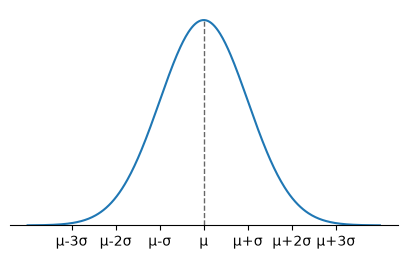

In [13]:
# Forma da densidade normal: simétrica em torno da média μ
z_graf = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(z_graf, norm.pdf(z_graf), color="tab:blue")
ax.vlines(0, 0, norm.pdf(0), color="0.4", ls="--", lw=1)
ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
ax.set_xticklabels(["μ-3σ", "μ-2σ", "μ-σ", "μ", "μ+σ", "μ+2σ", "μ+3σ"])
ax.set_yticks([])
ax.set_ylim(bottom=0)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

#### Propriedades:
- É simétrica em torno da média; por isso média, mediana e moda coincidem.
- Cada par (μ, σ) define uma curva normal diferente: μ indica onde ela está centrada e σ, quão espalhada ela é.
- A área total sob a curva é 1.
- O pico da curva fica em x = μ, e a densidade diminui à medida que nos afastamos da média.
- Com μ = 0 e σ² = 1, X ~ N(0, 1) é a normal padrão (ou reduzida), cuja densidade é:

$$f(x) = \frac{1}{\sqrt{2\pi}} e^{-\frac{x^2}{2}}$$

A integral dessa densidade não tem primitiva em termos de funções elementares, então as probabilidades são calculadas numericamente. Por isso existem tabelas da normal padrão (e, hoje, funções como `scipy.stats.norm`).

A figura a seguir mostra três normais com o mesmo desvio padrão (σ = 1) e médias diferentes (μ = 0, 1 e 2): a curva apenas se desloca.

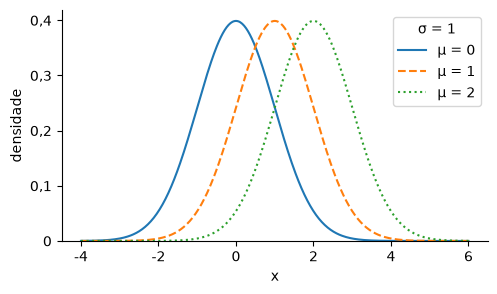

In [14]:
# Normais com desvio padrão 1 e médias 0, 1 e 2: a curva só se desloca
x_graf = np.linspace(-4, 6, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
for mu_graf, estilo in ((0, "-"), (1, "--"), (2, ":")):
    ax.plot(x_graf, norm.pdf(x_graf, mu_graf, 1), ls=estilo, label=f"μ = {mu_graf}")
ax.set_xlabel("x")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend(title="σ = 1")
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

Agora a média é a mesma (μ = 0) e os desvios padrão mudam (σ = 1, 2 e 3): quanto maior σ, mais baixa e espalhada a curva.

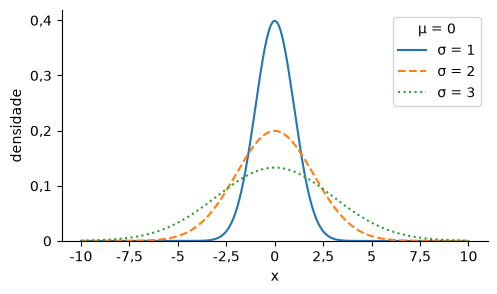

In [15]:
# Normais com média 0 e desvios padrão 1, 2 e 3: quanto maior σ, mais achatada
x_graf = np.linspace(-10, 10, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
for sigma_graf, estilo in ((1, "-"), (2, "--"), (3, ":")):
    ax.plot(x_graf, norm.pdf(x_graf, 0, sigma_graf), ls=estilo, label=f"σ = {sigma_graf}")
ax.set_xlabel("x")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend(title="μ = 0")
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

#### Regra 68–95–99,7
Para qualquer normal N(μ; σ²), cerca de 68% da área fica entre μ − σ e μ + σ, cerca de 95% entre μ − 2σ e μ + 2σ, e cerca de 99,7% entre μ − 3σ e μ + 3σ. Em outras palavras, só uns 5% dos valores se afastam da média mais de 2σ, e valores além de 3σ são raros.

#### Distribuição Normal Padrão
Para calcular probabilidades de qualquer normal usamos a normal padrão, Z ~ N(0, 1). Se X ~ N(μ, σ²), a variável padronizada

$$z = \frac{x - \mu}{\sigma}$$

tem distribuição normal padrão: z mede quantos desvios padrão o valor x está acima (ou abaixo) da média μ.

Há vários formatos de tabela da normal padrão. A que usamos aqui dá a probabilidade de Z ficar entre 0 e um valor positivo z:

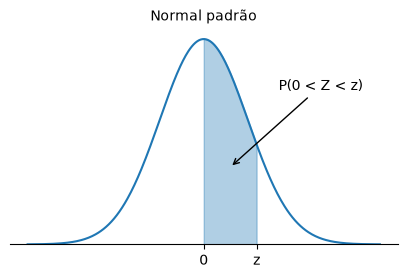

In [16]:
# A tabela usada a seguir dá a área entre 0 e um valor z positivo
z_graf = np.linspace(-4, 4, 400)
z_ilustrativo = 1.2
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(z_graf, norm.pdf(z_graf), color="tab:blue")
z_area = np.linspace(0, z_ilustrativo, 200)
ax.fill_between(z_area, norm.pdf(z_area), color="tab:blue", alpha=0.35)
ax.annotate("P(0 < Z < z)", xy=(0.6, 0.15), xytext=(1.7, 0.3), arrowprops=dict(arrowstyle="->"))
ax.set_xticks([0, z_ilustrativo])
ax.set_xticklabels(["0", "z"])
ax.set_yticks([])
ax.set_ylim(bottom=0)
ax.set_title("Normal padrão", fontsize=10)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

| z   | 0      | 1      | 2      | 3      | 4      | 5      | 6      | 7      | 8      | 9      |
|-----|--------|--------|--------|--------|--------|--------|--------|--------|--------|--------|
| 0,0 | 0,0000 | 0,0040 | 0,0080 | 0,0120 | 0,0160 | 0,0199 | 0,0239 | 0,0279 | 0,0319 | 0,0359 |
| 0,1 | 0,0398 | 0,0438 | 0,0478 | 0,0517 | 0,0557 | 0,0596 | 0,0636 | 0,0675 | 0,0714 | 0,0753 |
| 0,2 | 0,0793 | 0,0832 | 0,0871 | 0,0910 | 0,0948 | 0,0987 | 0,1026 | 0,1064 | 0,1103 | 0,1141 |
| 0,3 | 0,1179 | 0,1217 | 0,1255 | 0,1293 | 0,1331 | 0,1368 | 0,1406 | 0,1443 | 0,1480 | 0,1517 |
| 0,4 | 0,1554 | 0,1591 | 0,1628 | 0,1664 | 0,1700 | 0,1736 | 0,1772 | 0,1808 | 0,1844 | 0,1879 |
| 0,5 | 0,1915 | 0,1950 | 0,1985 | 0,2019 | 0,2054 | 0,2088 | 0,2123 | 0,2157 | 0,2190 | 0,2224 |
| 0,6 | 0,2257 | 0,2291 | 0,2324 | 0,2357 | 0,2389 | 0,2422 | 0,2454 | 0,2486 | 0,2517 | 0,2549 |
| 0,7 | 0,2580 | 0,2611 | 0,2642 | 0,2673 | 0,2704 | 0,2734 | 0,2764 | 0,2794 | 0,2823 | 0,2852 |
| 0,8 | 0,2881 | 0,2910 | 0,2939 | 0,2967 | 0,2995 | 0,3023 | 0,3051 | 0,3078 | 0,3106 | 0,3133 |
| 0,9 | 0,3159 | 0,3186 | 0,3212 | 0,3238 | 0,3264 | 0,3289 | 0,3315 | 0,3340 | 0,3365 | 0,3389 |
| 1,0 | 0,3413 | 0,3438 | 0,3461 | 0,3485 | 0,3508 | 0,3531 | 0,3554 | 0,3577 | 0,3599 | 0,3621 |
| 1,1 | 0,3643 | 0,3665 | 0,3686 | 0,3708 | 0,3729 | 0,3749 | 0,3770 | 0,3790 | 0,3810 | 0,3830 |
| 1,2 | 0,3849 | 0,3869 | 0,3888 | 0,3907 | 0,3925 | 0,3944 | 0,3962 | 0,3980 | 0,3997 | 0,4015 |
| 1,3 | 0,4032 | 0,4049 | 0,4066 | 0,4082 | 0,4099 | 0,4115 | 0,4131 | 0,4147 | 0,4162 | 0,4177 |
| 1,4 | 0,4192 | 0,4207 | 0,4222 | 0,4236 | 0,4251 | 0,4265 | 0,4279 | 0,4292 | 0,4306 | 0,4319 |
| 1,5 | 0,4332 | 0,4345 | 0,4357 | 0,4370 | 0,4382 | 0,4394 | 0,4406 | 0,4418 | 0,4429 | 0,4441 |
| 1,6 | 0,4452 | 0,4463 | 0,4474 | 0,4484 | 0,4495 | 0,4505 | 0,4515 | 0,4525 | 0,4535 | 0,4545 |
| 1,7 | 0,4554 | 0,4564 | 0,4573 | 0,4582 | 0,4591 | 0,4599 | 0,4608 | 0,4616 | 0,4625 | 0,4633 |
| 1,8 | 0,4641 | 0,4649 | 0,4656 | 0,4664 | 0,4671 | 0,4678 | 0,4686 | 0,4693 | 0,4699 | 0,4706 |
| 1,9 | 0,4713 | 0,4719 | 0,4726 | 0,4732 | 0,4738 | 0,4744 | 0,4750 | 0,4756 | 0,4761 | 0,4767 |
| 2,0 | 0,4772 | 0,4778 | 0,4783 | 0,4788 | 0,4793 | 0,4798 | 0,4803 | 0,4808 | 0,4812 | 0,4817 |
| 2,1 | 0,4821 | 0,4826 | 0,4830 | 0,4834 | 0,4838 | 0,4842 | 0,4846 | 0,4850 | 0,4854 | 0,4857 |
| 2,2 | 0,4861 | 0,4864 | 0,4868 | 0,4871 | 0,4875 | 0,4878 | 0,4881 | 0,4884 | 0,4887 | 0,4890 |
| 2,3 | 0,4893 | 0,4896 | 0,4898 | 0,4901 | 0,4904 | 0,4906 | 0,4909 | 0,4911 | 0,4913 | 0,4916 |
| 2,4 | 0,4918 | 0,4920 | 0,4922 | 0,4925 | 0,4927 | 0,4929 | 0,4931 | 0,4932 | 0,4934 | 0,4936 |
| 2,5 | 0,4938 | 0,4940 | 0,4941 | 0,4943 | 0,4945 | 0,4946 | 0,4948 | 0,4949 | 0,4951 | 0,4952 |
| 2,6 | 0,4953 | 0,4955 | 0,4956 | 0,4957 | 0,4959 | 0,4960 | 0,4961 | 0,4962 | 0,4963 | 0,4964 |
| 2,7 | 0,4965 | 0,4966 | 0,4967 | 0,4968 | 0,4969 | 0,4970 | 0,4971 | 0,4972 | 0,4973 | 0,4974 |
| 2,8 | 0,4974 | 0,4975 | 0,4976 | 0,4977 | 0,4977 | 0,4978 | 0,4979 | 0,4979 | 0,4980 | 0,4981 |
| 2,9 | 0,4981 | 0,4982 | 0,4982 | 0,4983 | 0,4984 | 0,4984 | 0,4985 | 0,4985 | 0,4986 | 0,4986 |
| 3,0 | 0,4987 | 0,4987 | 0,4987 | 0,4988 | 0,4988 | 0,4989 | 0,4989 | 0,4989 | 0,4990 | 0,4990 |
| 3,1 | 0,4990 | 0,4991 | 0,4991 | 0,4991 | 0,4992 | 0,4992 | 0,4992 | 0,4992 | 0,4993 | 0,4993 |
| 3,2 | 0,4993 | 0,4993 | 0,4994 | 0,4994 | 0,4994 | 0,4994 | 0,4994 | 0,4995 | 0,4995 | 0,4995 |
| 3,3 | 0,4995 | 0,4995 | 0,4995 | 0,4996 | 0,4996 | 0,4996 | 0,4996 | 0,4996 | 0,4996 | 0,4997 |
| 3,4 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4998 |
| 3,5 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 |

#### Exemplos:
Sendo Z ~ N(0, 1), calcule as probabilidades a seguir:

- a) P(-1,5 < Z < 0)

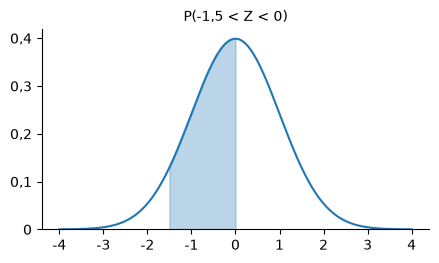

In [17]:
area_normal(-1.5, 0, "P(-1,5 < Z < 0)")

Consulta à tabela da normal padrão: linha 1,5 e coluna 0 → 0,4332 (área entre 0 e 1,5). O mesmo valor, calculado com o `scipy`, está na célula de código abaixo.

Resposta:

    Já que a curva da distribuição normal é simétrica em torno da média, então 
    P(-1,5<Z<0) = P(0<Z<1,5) = 0,4332 

In [18]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 1.5) = {:.4f}".format(norm.cdf(1.5) - 0.5))

P(0 < Z < 1.5) = 0.4332


In [12]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -1.5
b_Nor = 0

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.4331927987311419

- b) P(0 < Z < 0,83)

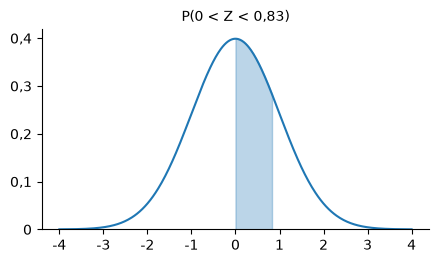

In [19]:
area_normal(0, 0.83, "P(0 < Z < 0,83)")

Consulta à tabela da normal padrão: linha 0,8 e coluna 3 → 0,2967 (área entre 0 e 0,83). O mesmo valor, calculado com o `scipy`, está na célula de código abaixo.

Resposta:

    P(0<Z<0,83)=0,2967

In [20]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.83) = {:.4f}".format(norm.cdf(0.83) - 0.5))

P(0 < Z < 0.83) = 0.2967


In [20]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = 0
b_Nor = 0.83

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.29673060817193164

- c) P(Z > -0,23)

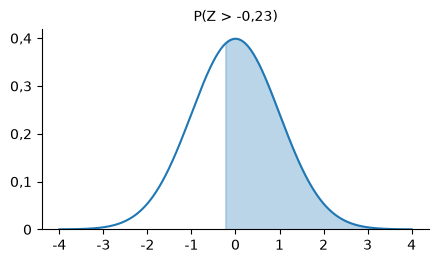

In [21]:
area_normal(-0.23, np.inf, "P(Z > -0,23)")

Consulta à tabela da normal padrão: linha 0,2 e coluna 3 → 0,0910 (área entre 0 e 0,23). O mesmo valor, calculado com o `scipy`, está na célula de código abaixo.

Resposta:

    P(-0,23<Z<0) = 0,0910
    Para encontrar P(Z>-0,23) = P(-0,23<Z<0) + 0,5 = 0,5910
    Foi necessário somar 0,5 à probabilidade porque P(Z>0) =0,5.

In [22]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.23) = {:.4f}".format(norm.cdf(0.23) - 0.5))

P(0 < Z < 0.23) = 0.0910


In [24]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -0.23
b_Nor = np.inf #infinito positivo

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.5909541151420056

- d) P(Z < 1,20)

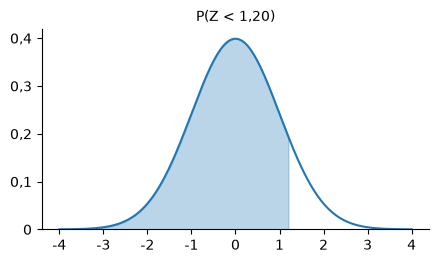

In [23]:
area_normal(-np.inf, 1.2, "P(Z < 1,20)")

Consulta à tabela da normal padrão: linha 1,2 e coluna 0 → 0,3849 (área entre 0 e 1,20). O mesmo valor, calculado com o `scipy`, está na célula de código abaixo.

Resposta:

    P(0<Z<1,20) = 0,3849
    Para encontrar P(Z<1,20) = P(0<Z<1,20) + 0,5 = 0,8849.
    Foi necessário somar 0,5 à probabilidade porque P(Z<0) =0,5.

In [24]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 1.20) = {:.4f}".format(norm.cdf(1.20) - 0.5))

P(0 < Z < 1.20) = 0.3849


In [28]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -np.inf #infinito negativo
b_Nor = 1.2

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8849303297782929

- e) P(-1,98 < Z < 0,49)

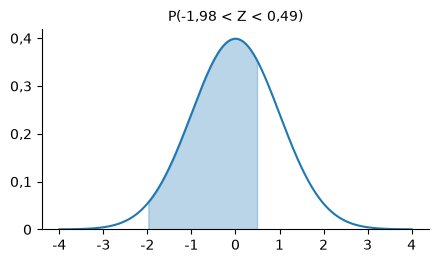

In [25]:
area_normal(-1.98, 0.49, "P(-1,98 < Z < 0,49)")

Consulta à tabela da normal padrão: linha 0,4 e coluna 9 → 0,1879 (área entre 0 e 0,49); linha 1,9 e coluna 8 → 0,4761 (área entre 0 e 1,98). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(0<Z<0,49) = 0,1879
    P(-1,98<Z<0) = 0,4761
    Para encontrar P(-1,98<Z<0,49) = P(-1,98<Z<0) + P(0<Z<0,49) ≈ 0,6641 (somando os valores arredondados da tabela, 0,4761 + 0,1879, obtém-se 0,6640).

In [26]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.49) = {:.4f}".format(norm.cdf(0.49) - 0.5))
print("P(0 < Z < 1.98) = {:.4f}".format(norm.cdf(1.98) - 0.5))

P(0 < Z < 0.49) = 0.1879
P(0 < Z < 1.98) = 0.4761


In [29]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -1.98
b_Nor = 0.49

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.6640812862411007

- f) P(0,52 < Z < 1,22)

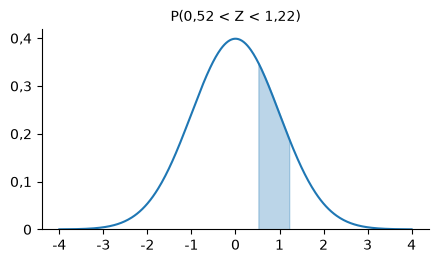

In [27]:
area_normal(0.52, 1.22, "P(0,52 < Z < 1,22)")

Consulta à tabela da normal padrão: linha 0,5 e coluna 2 → 0,1985 (área entre 0 e 0,52); linha 1,2 e coluna 2 → 0,3888 (área entre 0 e 1,22). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(0<Z<0,52) = 0,1985
    P(0<Z<1,22) = 0,3888
    Para encontrar P(0,52<Z<1,22) = P(0<Z<1,22) - P(0<Z<0,52) = 0,1903.

In [28]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.52) = {:.4f}".format(norm.cdf(0.52) - 0.5))
print("P(0 < Z < 1.22) = {:.4f}".format(norm.cdf(1.22) - 0.5))

P(0 < Z < 0.52) = 0.1985
P(0 < Z < 1.22) = 0.3888


In [30]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = 0.52
b_Nor = 1.22

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.1902993500991316

- g) P(-1,75 < Z < -1,04)

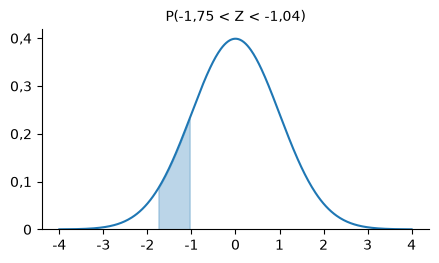

In [29]:
area_normal(-1.75, -1.04, "P(-1,75 < Z < -1,04)")

Consulta à tabela da normal padrão: linha 1,7 e coluna 5 → 0,4599 (área entre 0 e 1,75); linha 1,0 e coluna 4 → 0,3508 (área entre 0 e 1,04). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(-1,75<Z<0)=0,4599
    P(-1,04<Z<0)=0,3508
    Para encontrar P(-1,75<Z<-1,04) = P(-1,75<Z<0) - P(-1,04<Z<0) = 0,1091.

In [30]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 1.75) = {:.4f}".format(norm.cdf(1.75) - 0.5))
print("P(0 < Z < 1.04) = {:.4f}".format(norm.cdf(1.04) - 0.5))

P(0 < Z < 1.75) = 0.4599
P(0 < Z < 1.04) = 0.3508


In [31]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -1.75
b_Nor = -1.04

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.10911079346716433

#### Exemplo:
O tempo de entrega de um restaurante segue, aproximadamente, uma distribuição normal com média de 30 minutos e variância de 16 minutos² (desvio padrão de 4 minutos). Qual é a probabilidade de uma entrega:

- a) Levar no máximo 35 minutos.
    Graficamente, a probabilidade desejada pode ser representada da seguinte maneira:

$$P(X \le 35) = P\left(Z \le \frac{35 - 30}{4}\right) = P(Z \le 1{,}25) = 0{,}5 + 0{,}3944 = 0{,}8944$$

(Como a variância é 16, o desvio padrão é 4.)

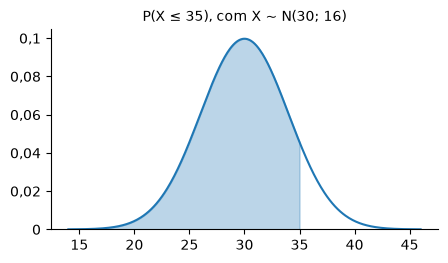

In [31]:
area_normal(-np.inf, 35, "P(X ≤ 35), com X ~ N(30; 16)", mu=30, sigma=4)

In [75]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 30
Variancia_Nor = 16


#Cálculo solicitado no enunciado P(X <= 35)
x_Nor_1 = -np.inf
x_Nor_2 = 35


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  1.25


In [76]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.894350226333146

- b) Levar pelo menos 38 minutos.

$$P(X \ge 38) = P\left(Z \ge \frac{38 - 30}{4}\right) = P(Z \ge 2{,}00) = 0{,}5 - 0{,}4772 = 0{,}0228$$

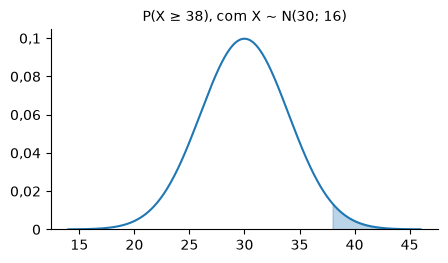

In [32]:
area_normal(38, np.inf, "P(X ≥ 38), com X ~ N(30; 16)", mu=30, sigma=4)

In [77]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 30
Variancia_Nor = 16


#Cálculo solicitado no enunciado P(X >= 38)
x_Nor_1 = 38
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  2.0
Z superior:  inf


In [78]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.02275013194817598

- c) Levar entre 28 e 32 minutos.

$$P(28 < X < 32) = P\left(\frac{28 - 30}{4} < Z < \frac{32 - 30}{4}\right) = P(-0{,}50 < Z < 0{,}50) = 2 \cdot 0{,}19146 \approx 0{,}3829$$

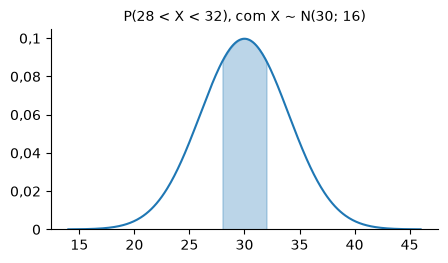

In [33]:
area_normal(28, 32, "P(28 < X < 32), com X ~ N(30; 16)", mu=30, sigma=4)

In [79]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 30
Variancia_Nor = 16


#Cálculo solicitado no enunciado P(28 < X < 32)
x_Nor_1 = 28
x_Nor_2 = 32


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.5
Z superior:  0.5


In [80]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.3829249225480263

- d) Levar mais de 25 minutos.

$$P(X > 25) = P\left(Z > \frac{25 - 30}{4}\right) = P(Z > -1{,}25) = 0{,}5 + 0{,}3944 = 0{,}8944$$

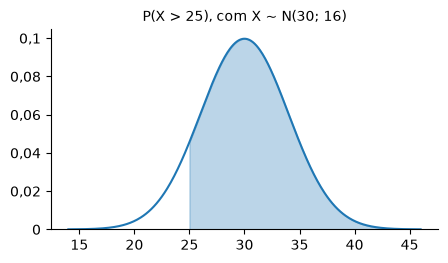

In [34]:
area_normal(25, np.inf, "P(X > 25), com X ~ N(30; 16)", mu=30, sigma=4)

In [83]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 30
Variancia_Nor = 16


#Cálculo solicitado no enunciado P(X > 25)
x_Nor_1 = 25
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -1.25
Z superior:  inf


In [84]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.894350226333146

#### Exercício 3:
A vida útil das baterias de um modelo de patinete elétrico segue, aproximadamente, uma distribuição normal com média de 400 dias e desvio padrão de 50 dias. Escolhendo uma bateria ao acaso, calcule a probabilidade de que ela dure:

- a) Entre 400 e 464 dias. R:0,3997

In [87]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(400 < X < 464)
x_Nor_1 = 400
x_Nor_2 = 464


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  0.0
Z superior:  1.28


In [88]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.399727432045558

- b) Entre 368,5 e 400 dias. R:0,2357

In [89]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(368.5 < X < 400)
x_Nor_1 = 368.5
x_Nor_2 = 400


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.63
Z superior:  0.0


In [90]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.23565270788432247

- c) Entre 343 e 442,5 dias. R:0,6752

In [93]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(343 < X < 442.5)
x_Nor_1 = 343
x_Nor_2 = 442.5


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -1.14
Z superior:  0.85


In [94]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.6751943063145093

- d) Menos de 367,5 dias. R:0,2578

In [95]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X < 367.5)
x_Nor_1 = -np.inf
x_Nor_2 = 367.5


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  -0.65


In [96]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.2578461108058647

- e) Mais de 485,5 dias. R:0,0436

In [97]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X > 485.5)
x_Nor_1 = 485.5
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  1.71
Z superior:  inf


In [98]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.043632936524031905

- f) Menos de 468,5 dias. R:0,9147

In [99]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X < 468.5)
x_Nor_1 = -np.inf
x_Nor_2 = 468.5


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  1.37


In [100]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.914656549178033

- g) Entre 438,5 e 471 dias. R:0,1428

In [101]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 400
Desvio_P_Nor = 50
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(438.5 < X < 471)
x_Nor_1 = 438.5
x_Nor_2 = 471


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  0.77
Z superior:  1.42


In [102]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.14284610581610319

#### Exercício 4:
O consumo diário de água de um condomínio segue, aproximadamente, uma distribuição normal com média de 12.000 litros e desvio padrão de 2.500 litros. Calcule a probabilidade de que, em um dia qualquer, o consumo:

- a) Seja superior a 9.000 litros. R:0,8849

In [104]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 12000
Desvio_P_Nor = 2500
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X > 9000)
x_Nor_1 = 9000
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -1.2
Z superior:  inf


In [105]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8849303297782929

- b) Seja inferior a 9.500 litros. R:0,1587

In [106]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 12000
Desvio_P_Nor = 2500
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X < 9500)
x_Nor_1 = -np.inf
x_Nor_2 = 9500


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  -1.0


In [107]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.15865525393145707

- c) Fique entre 11.000 e 13.000 litros. R:0,3108

In [108]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 12000
Desvio_P_Nor = 2500
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(11000 < X < 13000)
x_Nor_1 = 11000
x_Nor_2 = 13000


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.4
Z superior:  0.4


In [109]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.31084348322064836

- d) Fique entre 8.000 e 16.000 litros. R:0,8904

In [110]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 12000
Desvio_P_Nor = 2500
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(8000 < X < 16000)
x_Nor_1 = 8000
x_Nor_2 = 16000


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -1.6
Z superior:  1.6


In [111]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8904014166008839